# Demo of the GTM on 10-Dimensional R-Vine-Copula Data

In this demonstration we show how the GTM can be used to learn a probability distribution from synthetic data sampled from a 10 dimensional R-Vine-Copula as done in our [Paper](https://arxiv.org/pdf/2503.17845) Section 4.
To sample synthetic copula data we use the [pyvinecopulib](https://github.com/vinecopulib/pyvinecopulib) library.
Fore more details on copulas we refer to the Book [Analyzing Dependent Data with Vine Copulas](https://link.springer.com/book/10.1007/978-3-030-13785-4) for an comprehensive introduction to copulas and vine copulas.

In [1]:
from gtm import *

# Sample Copulas Package
import pyvinecopulib as pv
# Helpers to generate specfific vines and analyze there conditional independencies
from demos.pyvinecopulib_simulation_helpers import *

# Other Stuff
import numpy as np
import torch
from torch.utils.data import DataLoader
from demos.dataset_helpers import Generic_Dataset
from sklearn.metrics import roc_auc_score, roc_curve

import mlflow
import os

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1. Load Dragon Data as done in run_experiment_dragon.py

In [2]:
# Copy paste from run_experiment_dragon

train_portion=0.75
val_portion=0.15
test_portion=0.1


# have to set seed here as we dont do it in simualated data sampling
seed_value=1
set_seeds(seed_value)
    
data = pd.read_csv("/Users/matthiasherp/Desktop/phd_github_repositories/gtm/dragon_application/dragon_analysis_dataset_subset.csv")
    
shuffled_data = data.sample(frac=1, replace=False).reset_index(drop=True)
N = shuffled_data.shape[0]
D = shuffled_data.shape[1]
N_train = int(train_portion * N)
N_validate = int(val_portion * N)
N_test = int(test_portion * N)
data_train = shuffled_data.iloc[:N_train, :]
data_validate = shuffled_data.iloc[N_train:N_train + N_validate, :]
data_test = shuffled_data.iloc[N_train + N_validate:N_train + N_validate + N_test, :]

data_train_numpy = data_train.to_numpy()
data_validate_numpy = data_validate.to_numpy()
data_test_numpy = data_test.to_numpy()

data_train_numpy_log = np.log(data_train_numpy + 0.01)
data_validate_numpy_log = np.log(data_validate_numpy + 0.01)
data_test_numpy_log = np.log(data_test_numpy + 0.01)

data_train_numpy_standardized = ((data_train_numpy_log - data_train_numpy_log.min(axis=0)) / (data_train_numpy_log.max(axis=0) - data_train_numpy_log.min(axis=0)) - 0.5) * 8
data_validate_numpy_standardized = ((data_validate_numpy_log - data_train_numpy_log.min(axis=0)) / (data_train_numpy_log.max(axis=0) - data_train_numpy_log.min(axis=0)) - 0.5) * 8
data_test_numpy_standardized = ((data_test_numpy_log - data_train_numpy_log.min(axis=0)) / (data_train_numpy_log.max(axis=0) - data_train_numpy_log.min(axis=0)) - 0.5) * 8
       
data_train_torch = torch.from_numpy(data_train_numpy_standardized).float() 
data_validate_torch = torch.from_numpy(data_validate_numpy_standardized).float() 
data_test_torch = torch.from_numpy(data_test_numpy_standardized).float() 
    

In [4]:
dataset_train = Generic_Dataset(data_train_torch)
dataloader_train = DataLoader(dataset_train, batch_size=N_train)

dataset_validate = Generic_Dataset(data_validate_torch)
dataloader_validate = DataLoader(dataset_validate, batch_size=N_validate)
        

In [5]:
#model.plot_marginals(data_train_torch)

### 2. Run marginal transform only GTM and Store transformed data and log_d for the two step tm + gauss lasso model

In [28]:
model_marginals_only = GTM(
        number_variables = D,
        number_transformation_layers = 1,
        number_decorrelation_layers= 0,
        degree_transformations = 15,
        degree_decorrelation = 10,
        spline_transformation = "bspline",
        spline_decorrelation = "bspline",
        transformation_spline_range = (-5, 5),
        decorrelation_spline_range = (-10, 10),
        device = "cpu")

In [29]:

penalty_splines_params=torch.FloatTensor([
                            0, #study.best_params["penalty_decorrelation_ridge_param"],
                            0, #study.best_params["penalty_decorrelation_ridge_first_difference"],
                            0, #study.best_params["penalty_decorrelation_ridge_second_difference"],
                            0 #study.best_params["penalty_transformation_ridge_second_difference"]
                              ])

# pretrain the marginal transformations
_ = model_marginals_only.pretrain_transformation_layer(dataloader_train, dataloader_validate, iterations=1000, max_batches_per_iter=False, penalty_splines_params=penalty_splines_params)

  0%|          | 0/1000 [00:00<?, ?it/s]/Users/matthiasherp/Desktop/phd_github_repositories/gtm/gtm/gtm_splines/bspline_prediction_vectorized.py:764: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3687.)
  x=input_a_clone.T, t=knots.T, c=params_a.T, p=order, d=derivativ
  3%|▎         | 31/1000 [00:01<00:49, 19.72it/s]


KeyboardInterrupt: 




In [8]:
z_tilde_train = model_marginals_only.after_transformation(data_train_torch).detach()
model_marginals_only.plot_marginals(z_tilde_train)

plotting data after marignal transformations just to see how gaussian the dependence is

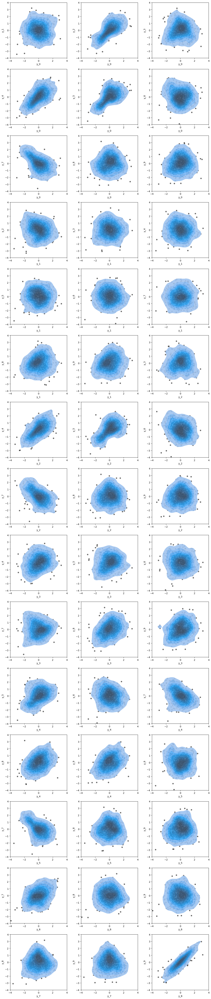

In [ ]:
model.plot_densities(z_tilde_train[:,0:10], x_lim=[-4,4], y_lim=[-4,4])

### 3. Run GGM and GM on the marginally transformed data

In [30]:
return_dict = model_marginals_only.forward(data_train_torch)
z_tilde_train = return_dict["output"]
train_log_d = return_dict["log_d"]

return_dict = model_marginals_only.forward(data_validate_torch)
z_tilde_validate = return_dict["output"]
validate_log_d = return_dict["log_d"]

return_dict = model_marginals_only.forward(data_test_torch)
z_tilde_test = return_dict["output"]
test_log_d = return_dict["log_d"]

In [31]:
from inverse_covariance import QuicGraphLassoCV, QuicGraphicalLassoCV, QuicGraphicalLasso
from sklearn.preprocessing import StandardScaler

def p_to_corr(matrix):

    diag_sqrt = np.diag(matrix).reshape(matrix.shape[0],1) ** 0.5
    matrix_std_multiplied = diag_sqrt @ diag_sqrt.T
            
    return -1 * matrix / matrix_std_multiplied
        
    
#y_all = torch.vstack([data_train_torch, data_validate_torch])
#
## marginal transformation of the data
#import numpy as np
#from scipy import stats
#from scipy.stats import norm
#
#def cdf_transform_to_gaussian(x):
    """
    Transform data to Gaussian using the empirical CDF (Probability Integral Transform)
    x: np.array of shape (n_samples,) or (n_samples, n_features)
    """
    if x.ndim == 1:
        x = x.reshape(-1, 1)
        squeeze = True
    else:
        squeeze = False

    n, d = x.shape
    x_gaussian = np.zeros_like(x, dtype=float)

    for j in range(d):
        # Step 1: Empirical CDF -> Uniform
        # Rank transform with adjustment to avoid 0 and 1
        ranks = stats.rankdata(x[:, j])
        uniform = ranks / (n + 1)  # avoids 0 and 1 (which would give ±inf)

        # Step 2: Uniform -> Gaussian via inverse normal CDF (probit)
        x_gaussian[:, j] = norm.ppf(uniform)

    if squeeze:
        return x_gaussian.squeeze()
    return x_gaussian
#
##y_all = torch.tensor(cdf_transform_to_gaussian(y_all))

# train a gtm to transform marginals properly to gaussian
y_all = torch.vstack([z_tilde_train, z_tilde_validate]).detach()

    
Y_all = y_all.numpy() # no need to normalize as done by marginal tms 
# Normalize the data
#scaler = StandardScaler()
Y_all_norm = Y_all# scaler.fit_transform(Y_all)


###########################################################################
############ GGM
###########################################################################

cv_model = QuicGraphicalLassoCV(lams=np.array([0.5,0.1,0.01,0.001])).fit(Y_all_norm)
cov = QuicGraphicalLasso(lam=cv_model.lam_,
                         ).fit(Y_all)
    #lam=int or np.ndarray,  # (optional) Initial penalty (scalar or matrix) 
    #lams=int or list,       # If int, determines the number of grid points 
                            # per refinement
    #n_refinements=int,      # Number of times the grid is refined
    #cv=int,                 # Number of folds or sklearn CV object
    #score_metric=str,       # One of 'log_likelihood' (default), 'frobenius', 
                            #        'kl', or 'quadratic'
    #init_method=str,        # Initial covariance estimate: 'corrcoef' or 'cov'
    # # X is data matrix (n_samples, n_features) 
    
p_matrix = cov.precision_ #emp_cov

p_matrix = np.around(p_matrix, decimals=3) #get_precision(), decimals=3)

# Get the lower triangular indices, including the diagonal
lower_triangular_indices = np.tril_indices_from(p_matrix, k=-1)

# results in the precision matrix elements being the conditional correlations
p_matrix = p_matrix
c_matrix = p_to_corr(p_matrix)
# Extract the corresponding entries from the precision matrix
entries_abs = np.abs(p_matrix[lower_triangular_indices])
entries_abs_c = np.abs(c_matrix[lower_triangular_indices])

###########################################################################
############ GM
###########################################################################

# Plain Gaussian: use empirical covariance
emp_cov = np.cov(Y_all_norm, rowvar=False)
gm_precision = np.linalg.inv(emp_cov)
gm_precision = np.around(gm_precision, decimals=3)
gm_c_matrix = p_to_corr(gm_precision)

lower_triangular_indices = np.tril_indices_from(gm_precision, k=-1)
gm_entries_abs = np.abs(gm_precision[lower_triangular_indices])
gm_entries_abs_c = np.abs(gm_c_matrix[lower_triangular_indices])

###########################################################################

# Create a list of tuples (row_number, col_number, precision_matrix_entry)
data = list(zip(lower_triangular_indices[0], lower_triangular_indices[1], entries_abs, entries_abs_c,
                gm_entries_abs, gm_entries_abs_c))
# Convert the list of tuples into a Pandas DataFrame
df_ggm = pd.DataFrame(data, columns=['var_row', 'var_col', 'ggm_p_matrix_abs', 'ggm_c_matrix_abs', 'gm_p_matrix_abs', 'gm_c_matrix_abs'])

In [32]:
cv_model.lam_

0.01

In [33]:
# compute log likelihoods for the GGM and GM models
# Gaussian log likelihood + log_d
# test set:

covariance_ggm = torch.inverse(torch.tensor(p_matrix))
dist = torch.distributions.MultivariateNormal(
    loc=torch.zeros(D),
    covariance_matrix=covariance_ggm
)
log_lik_ggm_test = dist.log_prob(z_tilde_test).mean().detach() + test_log_d.mean().detach()
print(log_lik_ggm_test)


dist = torch.distributions.MultivariateNormal(
    loc=torch.zeros(D),
    covariance_matrix=torch.tensor(emp_cov)
)
log_lik_gm_test = dist.log_prob(z_tilde_test).mean().detach() + test_log_d.mean().detach()
print(log_lik_gm_test)

tensor(-117.2833, dtype=torch.float64)
tensor(-121.0352, dtype=torch.float64)


### 4. Get Runs for Dragon from server with and without adpative lasso penalty

Note: found out that we need to increase the penalty upper bound from 30 to 1000 for the ridge penalties and from 1 to 10 for the lasso penalty
Without increase runs can be found in experiment dragon_application_version2. with in dragon_application_version3

In [6]:
os.getcwd()
os.chdir("..")
os.getcwd()

'/Users/matthiasherp/Desktop/phd_github_repositories/gtm'

old runs just for log likelihood comparison:

In [7]:
mlflow.set_tracking_uri("file:mlruns_scratch")
experiment = mlflow.get_experiment_by_name("dragon_application_version2")

print (experiment.experiment_id)

runs_df = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

545706101926912513


In [8]:
runs_df[["metrics.log_likelihood_test_gtm", "metrics.log_likelihood_test_gaussian", 
         "params.penalty_decorrelation_ridge_first_difference_chosen", # 0.0000001, 30,
         "params.penalty_decorrelation_ridge_second_difference_chosen", # 0.0000001, 30,
         "params.penalty_lasso_conditional_independence_chosen", # 0.0000001, 1,
         "tags.mlflow.runName"]]

,metrics.log_likelihood_test_gtm,metrics.log_likelihood_test_gaussian,params.penalty_decorrelation_ridge_first_difference_chosen,params.penalty_decorrelation_ridge_second_difference_chosen,params.penalty_lasso_conditional_independence_chosen,tags.mlflow.runName
0,-124.781349,-131.010101,28.997917579567787,20.18006758343408,0.9629007577896118,dragon_adaptive_correct
1,-125.824295,-131.010101,29.974106048533816,29.820289366586366,False,dragon_adaptive
2,-125.833961,-131.010101,29.955380012758532,29.818999013964763,False,dragon_no


In [9]:
mlflow.set_tracking_uri("file:mlruns_scratch")
experiment = mlflow.get_experiment_by_name("dragon_application_version3")

runs_df2 = mlflow.search_runs(experiment_ids=[experiment.experiment_id])

runs_df2

runs_df2[["metrics.log_likelihood_test_gtm", "metrics.log_likelihood_test_gaussian", 
         "params.penalty_decorrelation_ridge_first_difference_chosen", # 0.0000001, 30,
         "params.penalty_decorrelation_ridge_second_difference_chosen", # 0.0000001, 30,
         "params.penalty_lasso_conditional_independence_chosen", # 0.0000001, 1,
         "tags.mlflow.runName"]]

Traceback (most recent call last):
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 852, in _list_run_infos
    run_info = self._get_run_info_from_dir(r_dir)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 684, in _get_run_info_from_dir
    meta = FileStore._read_yaml(run_dir, FileStore.META_DATA_FILE_NAME)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", line 1109, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/mlflow/store/tracking/file_store.py", l

,metrics.log_likelihood_test_gtm,metrics.log_likelihood_test_gaussian,params.penalty_decorrelation_ridge_first_difference_chosen,params.penalty_decorrelation_ridge_second_difference_chosen,params.penalty_lasso_conditional_independence_chosen,tags.mlflow.runName
0,-121.843346,-131.010101,588.8903105177018,522.2474973638552,4.849552631378174,dragon_adaptive_correct
1,-124.377983,-131.010101,309.4735120466586,343.27796795014723,False,dragon_no


In [10]:
run_adaptive = runs_df[runs_df["tags.mlflow.runName"] == "dragon_adaptive_correct"]
run_no = runs_df[runs_df["tags.mlflow.runName"] == "dragon_no"]

In [11]:
run_adaptive2 = runs_df2[runs_df2["tags.mlflow.runName"] == "dragon_adaptive_correct"]
run_no2 = runs_df2[runs_df2["tags.mlflow.runName"] == "dragon_no"]

In [12]:
artifact_uri = run_adaptive["artifact_uri"].iloc[0][7:]
conditional_independence_table = pd.read_csv(artifact_uri+"/conditional_independence_table_model_samples.csv")

In [13]:
artifact_uri = run_no["artifact_uri"].iloc[0][7:]
conditional_independence_table_no = pd.read_csv(artifact_uri+"/conditional_independence_table_model_samples.csv")

In [14]:
artifact_uri = run_adaptive2["artifact_uri"].iloc[0][7:]
conditional_independence_table2 = pd.read_csv(artifact_uri+"/conditional_independence_table_model_samples.csv")

artifact_uri = run_no2["artifact_uri"].iloc[0][7:]
conditional_independence_table_no2 = pd.read_csv(artifact_uri+"/conditional_independence_table_model_samples.csv")

loading best model which is adpative lasso and higher possible penalties, best judged by test set log likelihood:

In [15]:
run_adaptive2["run_id"]

0    546960be679e4dcc9f797f6a01aa1292
Name: run_id, dtype: object

In [16]:
run_adaptive2["artifact_uri"].iloc[0][7:]

'/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch/785428291227008485/546960be679e4dcc9f797f6a01aa1292/artifacts'

In [17]:
model_uri = '/Users/matthiasherp/Desktop/phd_github_repositories/gtm/mlruns_scratch/785428291227008485/models/m-f04a97ffe5ee4579af495ba2429a50ce/artifacts' # source_run_id: 546960be679e4dcc9f797f6a01aa1292

In [18]:
model = mlflow.pytorch.load_model(model_uri, map_location=torch.device('cpu'))
model = model.to('cpu')

2026/08/06 14:01:47 WARNING mlflow.pytorch: Stored model version '2.2.2+cu121' does not match installed PyTorch version '2.5.1'


### 5. Log likelihood test set comparison

In [19]:
runs_df2[["metrics.log_likelihood_test_gtm", "metrics.log_likelihood_test_gaussian", "tags.mlflow.runName"]]

,metrics.log_likelihood_test_gtm,metrics.log_likelihood_test_gaussian,tags.mlflow.runName
0,-121.843346,-131.010101,dragon_adaptive_correct
1,-124.377983,-131.010101,dragon_no


In [20]:
runs_df[["metrics.log_likelihood_test_gtm", "metrics.log_likelihood_test_gaussian", "tags.mlflow.runName"]]

,metrics.log_likelihood_test_gtm,metrics.log_likelihood_test_gaussian,tags.mlflow.runName
0,-124.781349,-131.010101,dragon_adaptive_correct
1,-125.824295,-131.010101,dragon_adaptive
2,-125.833961,-131.010101,dragon_no


In [34]:
print(log_lik_ggm_test)
print(log_lik_gm_test)

tensor(-117.2833, dtype=torch.float64)
tensor(-121.0352, dtype=torch.float64)


### 5. Effect of penalty in runs ith lower and higher penalties and compared to GGM

first note that all metrics are pretty much the same in terms of ordering.
then lets look at the conditional correlations (pseudo for GTM)

In [22]:
conditional_independence_table[["precision_abs_mean",	"cond_correlation_abs_mean", "global_normed_hessian_abs_mean", "normed_hessian_abs_mean", "hessian_abs_mean", "hessian_mean"]].corr("spearman")

,precision_abs_mean,cond_correlation_abs_mean,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
precision_abs_mean,1.000000,0.996744,0.977003,0.971495,0.977061,0.211833
cond_correlation_abs_mean,0.996744,1.000000,0.975033,0.975656,0.975075,0.213311
global_normed_hessian_abs_mean,0.977003,0.975033,1.000000,0.996912,0.999999,0.227189
normed_hessian_abs_mean,0.971495,0.975656,0.996912,1.000000,0.996893,0.228274
hessian_abs_mean,0.977061,0.975075,0.999999,0.996893,1.000000,0.227176
hessian_mean,0.211833,0.213311,0.227189,0.228274,0.227176,1.000000


In [23]:
conditional_independence_table2[["precision_abs_mean",	"cond_correlation_abs_mean", "global_normed_hessian_abs_mean", "normed_hessian_abs_mean", "hessian_abs_mean", "hessian_mean"]].corr("spearman")

,precision_abs_mean,cond_correlation_abs_mean,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
precision_abs_mean,1.000000,0.997707,0.989069,0.987958,0.989107,0.199562
cond_correlation_abs_mean,0.997707,1.000000,0.984919,0.988989,0.984959,0.201105
global_normed_hessian_abs_mean,0.989069,0.984919,1.000000,0.996948,1.000000,0.198859
normed_hessian_abs_mean,0.987958,0.988989,0.996948,1.000000,0.996950,0.200409
hessian_abs_mean,0.989107,0.984959,1.000000,0.996950,1.000000,0.198869
hessian_mean,0.199562,0.201105,0.198859,0.200409,0.198869,1.000000


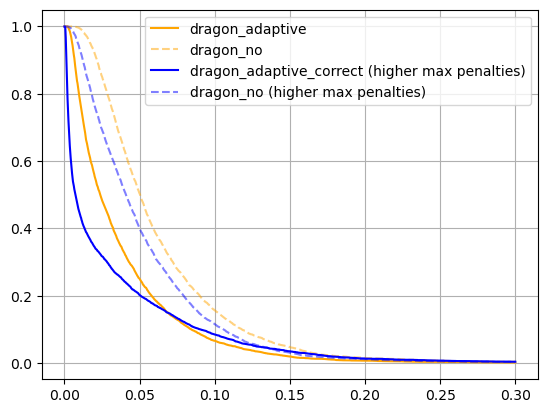

In [24]:
(conditional_independence_table["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='orange')


(conditional_independence_table_no["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table_no["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='orange', alpha=0.5, linestyle="dashed")

# Model with higher max penalties

(conditional_independence_table2["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table2["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='blue')


(conditional_independence_table_no2["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table_no2["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='blue', alpha=0.5, linestyle="dashed")

plt.legend(["dragon_adaptive", "dragon_no", "dragon_adaptive_correct (higher max penalties)", "dragon_no (higher max penalties)"])

# add grid
plt.grid()

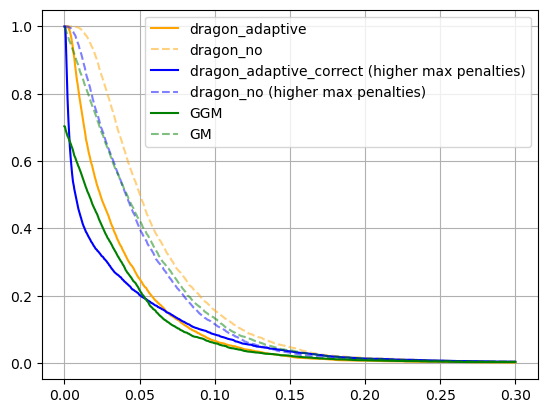

In [35]:
(conditional_independence_table["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='orange')


(conditional_independence_table_no["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table_no["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='orange', alpha=0.5, linestyle="dashed")

# Model with higher max penalties

(conditional_independence_table2["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table2["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='blue')


(conditional_independence_table_no2["cond_correlation_abs_mean"]> 0.2).mean()
# plot for differnt thresholds of conditional correlation the percentage of conditional independencies
threshold = np.linspace(0, 0.3, 1000)
percentages = [((conditional_independence_table_no2["cond_correlation_abs_mean"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='blue', alpha=0.5, linestyle="dashed")

# GM and GGM

threshold = np.linspace(0, 0.3, 1000)
percentages = [((df_ggm["ggm_c_matrix_abs"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='green')


threshold = np.linspace(0, 0.3, 1000)
percentages = [((df_ggm["gm_c_matrix_abs"] > t).mean()) for t in threshold]
plt.plot(threshold, percentages, color='green', alpha=0.5, linestyle="dashed")


plt.legend(["dragon_adaptive", "dragon_no", "dragon_adaptive_correct (higher max penalties)", "dragon_no (higher max penalties)", "GGM", "GM"])

# add grid
plt.grid()

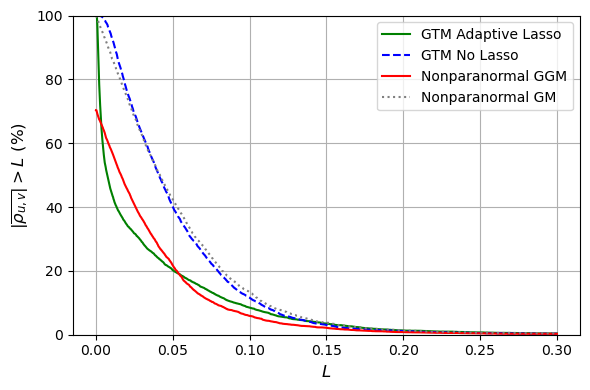

In [38]:
# create figure with desired size (width, height) in inches, and optional dpi
fig, ax = plt.subplots(figsize=(6,4))

threshold = np.linspace(0, 0.3, 1000)

# ── GTM Adaptive Lasso ────────────────────────────────────────────────────────
percentages_adaptive = [
    (conditional_independence_table2["cond_correlation_abs_mean"] > t).mean() * 100
    for t in threshold
]
plt.plot(threshold, percentages_adaptive, color='green', label="GTM Adaptive Lasso")

# ── GTM No Lasso ──────────────────────────────────────────────────────────────
percentages_no = [
    (conditional_independence_table_no2["cond_correlation_abs_mean"] > t).mean() * 100
    for t in threshold
]
plt.plot(threshold, percentages_no, color='blue', linestyle="dashed", label="GTM No Lasso")

# ── Nonparanormal GGM ─────────────────────────────────────────────────────────
percentages_ggm = [
    (df_ggm["ggm_c_matrix_abs"] > t).mean() * 100
    for t in threshold
]
plt.plot(threshold, percentages_ggm, color='red', label="Nonparanormal GGM")

# ── Nonparanormal GM ──────────────────────────────────────────────────────────
percentages_gm = [
    (df_ggm["gm_c_matrix_abs"] > t).mean() * 100
    for t in threshold
]
plt.plot(threshold, percentages_gm, color='grey', linestyle="dotted", label="Nonparanormal GM")

# ── Formatting ────────────────────────────────────────────────────────────────
plt.xlabel(r"$L$", fontsize=12)
plt.ylabel(r"$|\overline{\rho_{u,v}}| > L$ (%)", fontsize=12)
plt.ylim(0, 100)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

array([[1.        , 0.91130169],
       [0.91130169, 1.        ]])

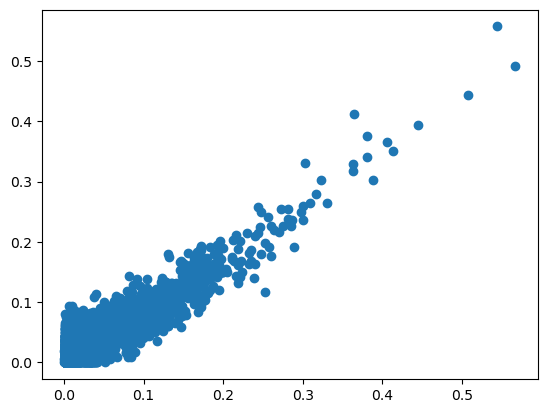

In [39]:
# plot from conditional_independence_table "cond_correlation_abs_mean" vs "global_normed_hessian_abs_mean"
plt.plot(conditional_independence_table2["cond_correlation_abs_mean"], df_ggm["ggm_c_matrix_abs"], 'o')
np.corrcoef(conditional_independence_table2["cond_correlation_abs_mean"], df_ggm["ggm_c_matrix_abs"], 'spearman')


#TODO: mit vorzeichen machen nicht abs

In [40]:
df_ggm

,var_row,var_col,ggm_p_matrix_abs,ggm_c_matrix_abs,gm_p_matrix_abs,gm_c_matrix_abs
0,1,0,0.118,0.044098,0.214,0.063038
1,2,0,0.088,0.020467,0.270,0.046472
2,2,1,0.063,0.020967,0.356,0.091113
3,3,0,0.211,0.080959,0.386,0.115802
4,3,1,0.028,0.015373,0.053,0.023644
...,...,...,...,...,...,...
4945,99,94,0.000,0.000000,0.387,0.076135
4946,99,95,0.132,0.050729,0.398,0.126207
4947,99,96,0.067,0.023640,0.296,0.088167
4948,99,97,0.000,0.000000,0.067,0.021905


### 6. Lets look at the strongest effects to see how nonlinear they are

In [41]:
synthetic_samples = model.sample(20000)

mask = (synthetic_samples.abs() <= 4).all(axis=1)
synthetic_samples = synthetic_samples[mask]

print(f"Rows kept    : {mask.sum().item()}")
print(f"Rows dropped : {(~mask).sum().item()}")

/Users/matthiasherp/Desktop/phd_github_repositories/gtm/gtm/gtm_model/gtm.py:1110: UserWarning: Transformation layer does not have an inverse. Inverse is approximated
  warnings.warn(


Rows kept    : 10678
Rows dropped : 9322


In [42]:
synthetic_samples = model.sample(10000)

In [43]:
local_pseudo_cond_corr_matrix = model.compute_pseudo_conditional_correlation_matrix(synthetic_samples)

In [44]:
gtm_adaptive_mean_cond_corr =  local_pseudo_cond_corr_matrix.mean(0).numpy()

c_matrix

array([[-1.        ,  0.04409796,  0.0204671 , ...,  0.03193854,
         0.01656477, -0.        ],
       [ 0.04409796, -1.        ,  0.02096699, ...,  0.05002536,
         0.05410517,  0.01942192],
       [ 0.0204671 ,  0.02096699, -1.        , ...,  0.03882073,
        -0.        , -0.        ],
       ...,
       [ 0.03193854,  0.05002536,  0.03882073, ..., -1.        ,
         0.09581249, -0.        ],
       [ 0.01656477,  0.05410517, -0.        , ...,  0.09581249,
        -1.        , -0.09587186],
       [-0.        ,  0.01942192, -0.        , ..., -0.        ,
        -0.09587186, -1.        ]])

In [45]:
model.num_trans_layers=0
synthetic_samples = model.sample(10000)
local_pseudo_cond_corr_matrix = model.compute_pseudo_conditional_correlation_matrix(synthetic_samples)
gtm_adaptive_mean_cond_corr =  local_pseudo_cond_corr_matrix.mean(0).numpy()
model.num_trans_layers=1

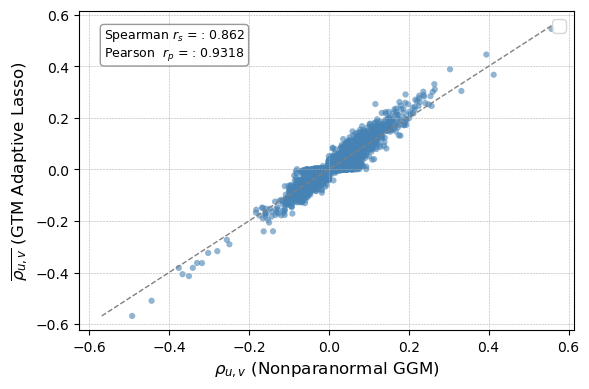

Spearman r_s   : 0.8622
Pearson  r_p   : 0.9318


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ── Extract lower triangular elements (excluding diagonal) ────────────────────

def get_lower_triangular(matrix):
    n = matrix.shape[0]
    idx = np.tril_indices(n, k=-1)
    return matrix[idx]

gtm_vals = get_lower_triangular(gtm_adaptive_mean_cond_corr)
c_vals   = get_lower_triangular(c_matrix)

# ── Compute rank correlations ─────────────────────────────────────────────────
spearman_r, spearman_p = stats.spearmanr(c_vals, gtm_vals)
pearson_r= np.corrcoef(c_vals, gtm_vals)[1,0]

# Convert to plain Python floats before using in f-strings
spearman_r = float(spearman_r)
pearson_r  = float(pearson_r)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(
    c_vals, gtm_vals,
    color="steelblue", alpha=0.6, s=20, edgecolors="none",
)

# Identity line for reference
lims = [
    min(c_vals.min(), gtm_vals.min()),
    max(c_vals.max(), gtm_vals.max()),
]
ax.plot(lims, lims, color="grey", linestyle="--", linewidth=1.0) #, label="Identity (y=x)")

# Annotation with rank correlations
ax.text(
    0.05, 0.95,
    f"Spearman $r_s$ = : {spearman_r:.3f}\n"
    f"Pearson  $r_p$ = : {pearson_r:.4f}",
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment="top",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="grey", alpha=0.8),
)

ax.set_xlabel(r"$\rho_{u,v}$ (Nonparanormal GGM)", fontsize=12)
ax.set_ylabel(r"$\overline{\rho_{u,v}}$ (GTM Adaptive Lasso)", fontsize=12)
ax.legend(fontsize=12)
ax.grid(True, linestyle="--", linewidth=0.4)
plt.tight_layout()
plt.show()

# ── Print summary ─────────────────────────────────────────────────────────────
print(f"Spearman r_s   : {spearman_r:.4f}")
print(f"Pearson  r_p   : {pearson_r:.4f}")

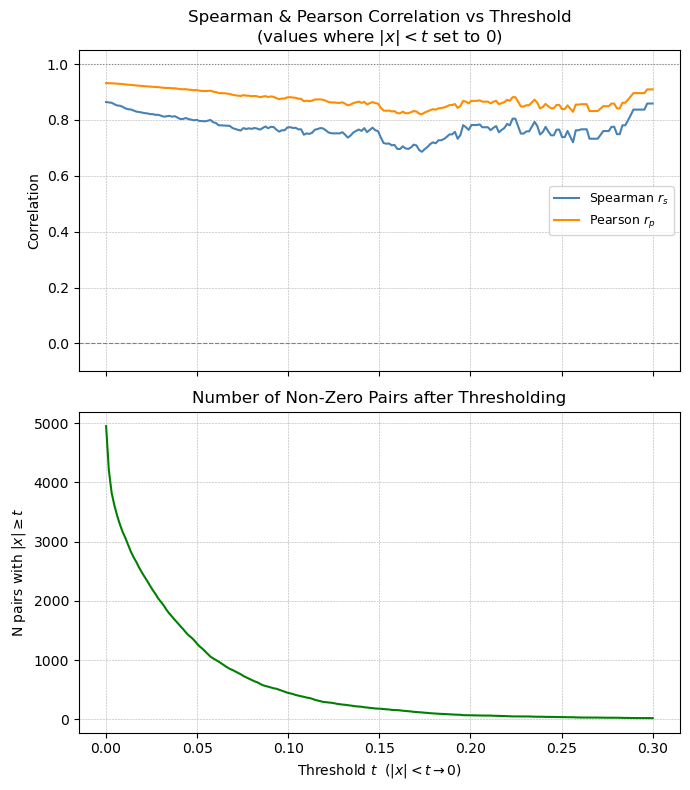

 Threshold |   Spearman |    Pearson |  N nonzero
------------------------------------------------
  0.00     |      0.864 |      0.932 |       4950
  0.05     |      0.800 |      0.907 |       1281
  0.10     |      0.773 |      0.881 |        448
  0.15     |      0.760 |      0.858 |        180
  0.20     |      0.782 |      0.868 |         65
  0.25     |      0.739 |      0.839 |         36


In [85]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ── Extract lower triangular elements ────────────────────────────────────────
def get_lower_triangular(matrix):
    n = matrix.shape[0]
    idx = np.tril_indices(n, k=-1)
    return matrix[idx]

gtm_vals = get_lower_triangular(gtm_adaptive_mean_cond_corr)
c_vals   = get_lower_triangular(c_matrix)

# ── Compute correlations for different thresholds ─────────────────────────────
# For each threshold t:
#   - set all values where |value| < t to 0 in BOTH vectors
#   - compute Spearman and Pearson correlation on thresholded vectors

thresholds = np.linspace(0, 0.3, 200)

spearman_rs = []
pearson_rs  = []
n_nonzero   = []

for t in thresholds:

    # Zero out values where absolute value is below threshold
    gtm_thresh = np.where(np.abs(gtm_vals) >= t, gtm_vals, 0.0)
    c_thresh   = np.where(np.abs(c_vals)   >= t, c_vals,   0.0)

    # Track how many pairs survive (at least one nonzero)
    nonzero_mask = (np.abs(gtm_thresh) > 0) | (np.abs(c_thresh) > 0)
    n_nonzero.append(nonzero_mask.sum())

    try:
        sr, _ = stats.spearmanr(c_thresh, gtm_thresh)
        pr, _ = stats.pearsonr(c_thresh,  gtm_thresh)
        spearman_rs.append(float(sr))
        pearson_rs.append(float(pr))
    except Exception:
        spearman_rs.append(np.nan)
        pearson_rs.append(np.nan)

spearman_rs = np.array(spearman_rs)
pearson_rs  = np.array(pearson_rs)
n_nonzero   = np.array(n_nonzero)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)

# Top: correlations vs threshold
axes[0].plot(thresholds, spearman_rs, color="steelblue",  linewidth=1.5, label="Spearman $r_s$")
axes[0].plot(thresholds, pearson_rs,  color="darkorange", linewidth=1.5, label="Pearson $r_p$")
axes[0].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[0].axhline(1, color="grey", linestyle=":",  linewidth=0.8)
axes[0].set_ylabel("Correlation")
axes[0].set_ylim(-0.1, 1.05)
axes[0].legend(fontsize=9)
axes[0].grid(True, linestyle="--", linewidth=0.4)
axes[0].set_title(
    "Spearman & Pearson Correlation vs Threshold\n"
    r"(values where $|x| < t$ set to 0)"
)

# Bottom: number of surviving pairs vs threshold
axes[1].plot(thresholds, n_nonzero, color="green", linewidth=1.5)
axes[1].set_xlabel(r"Threshold $t$  $(|x| < t \rightarrow 0)$")
axes[1].set_ylabel(r"N pairs with $|x| \geq t$")
axes[1].grid(True, linestyle="--", linewidth=0.4)
axes[1].set_title("Number of Non-Zero Pairs after Thresholding")

plt.tight_layout()
plt.show()

# ── Print key values ──────────────────────────────────────────────────────────
print(f"{'Threshold':>10} | {'Spearman':>10} | {'Pearson':>10} | {'N nonzero':>10}")
print("-" * 48)
for t in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25]:
    idx = np.argmin(np.abs(thresholds - t))
    print(
        f"  {t:.2f}     | "
        f"{spearman_rs[idx]:>10.3f} | "
        f"{pearson_rs[idx]:>10.3f} | "
        f"{n_nonzero[idx]:>10}"
    )

r: 9, c: 8


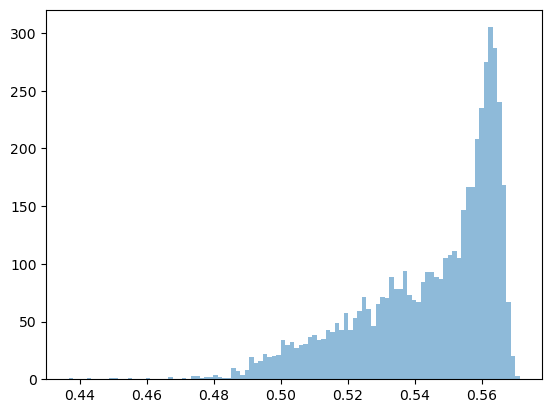

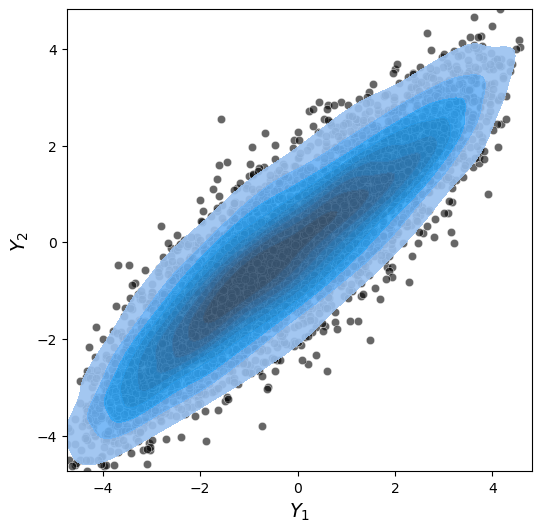

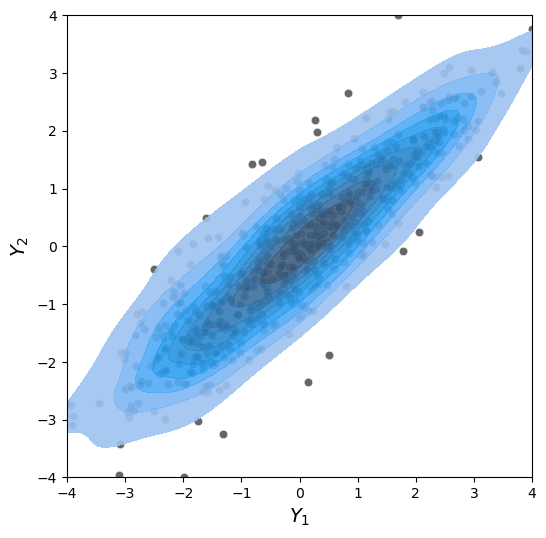

r: 11, c: 9


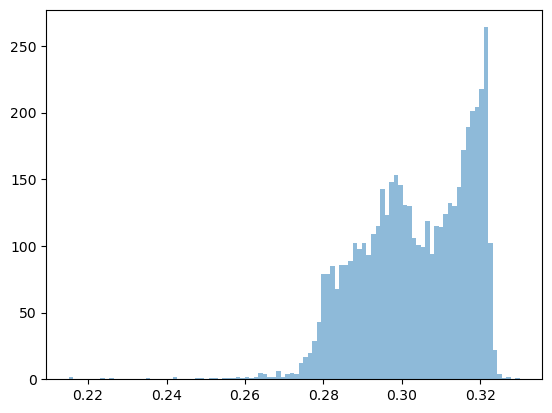

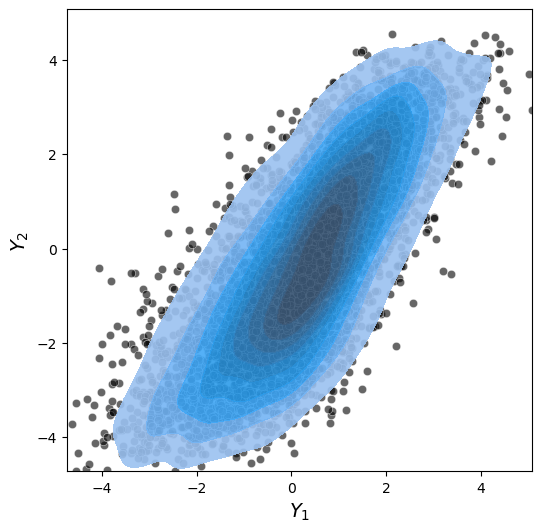

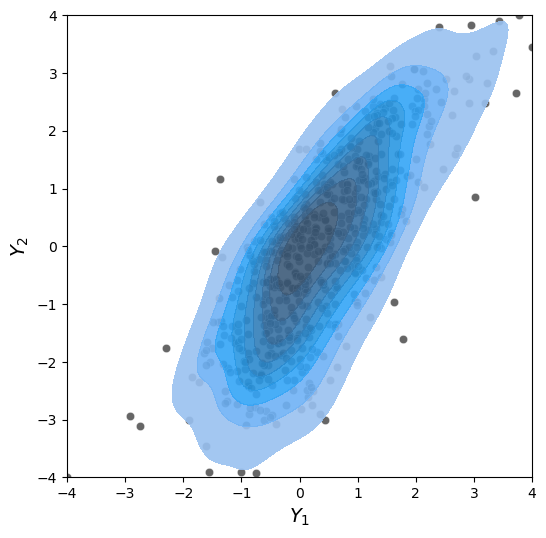

r: 14, c: 10


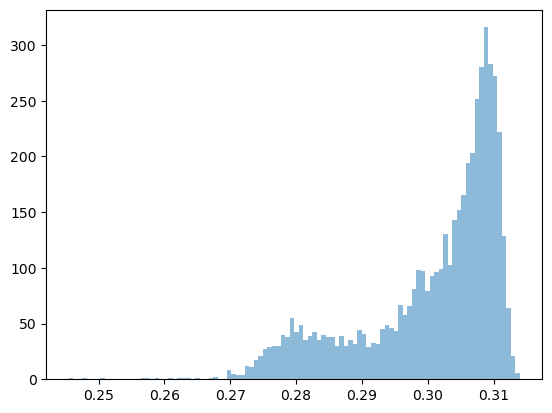

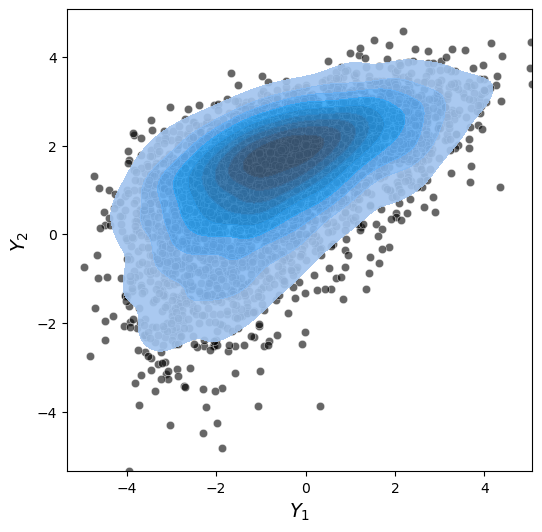

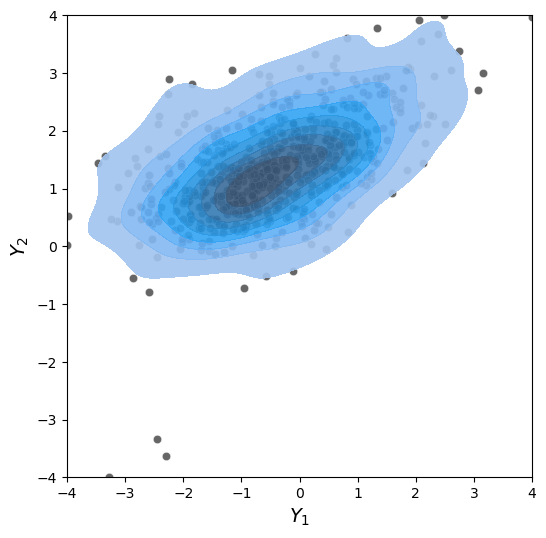

r: 20, c: 5


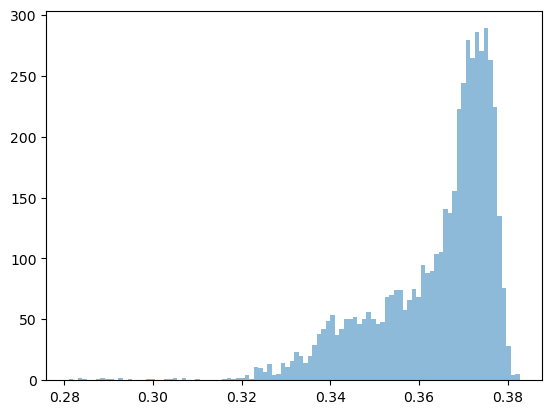

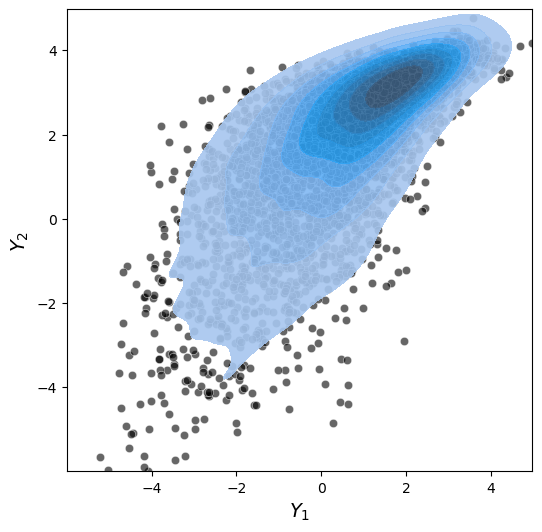

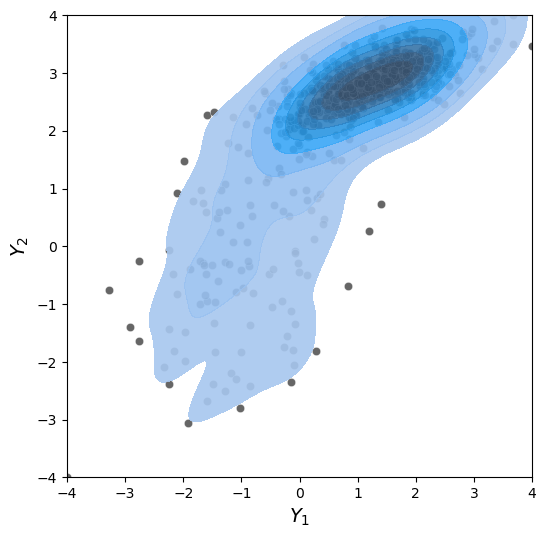

r: 31, c: 1


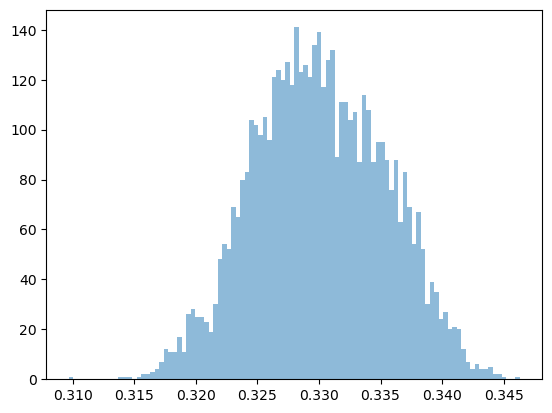

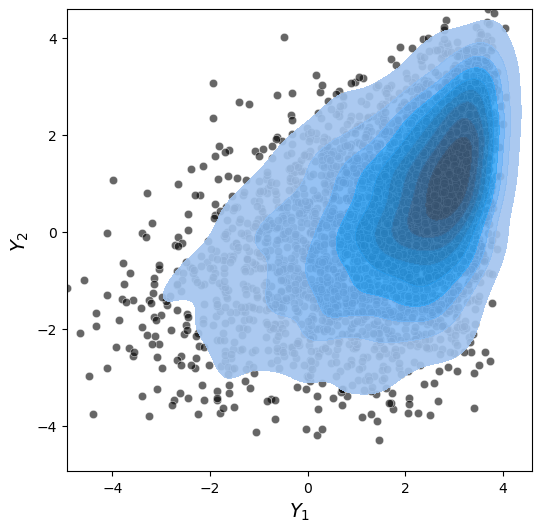

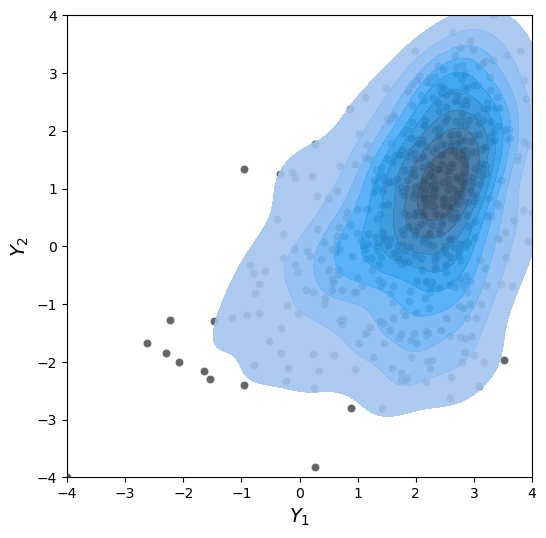

r: 47, c: 27


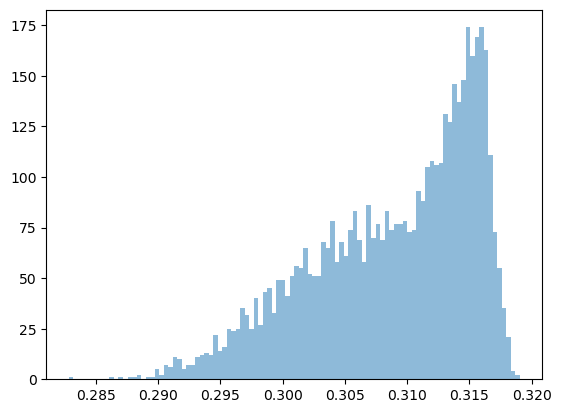

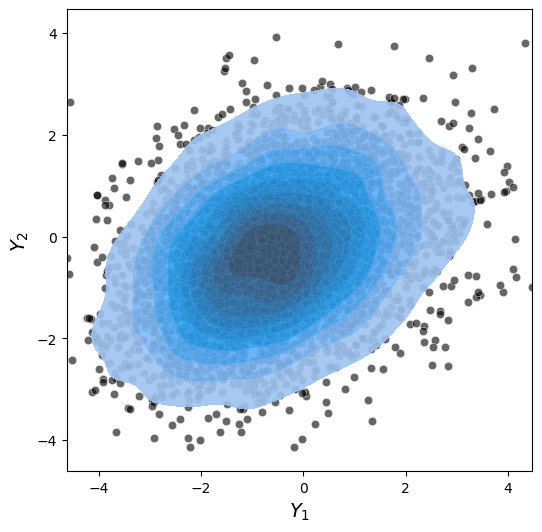

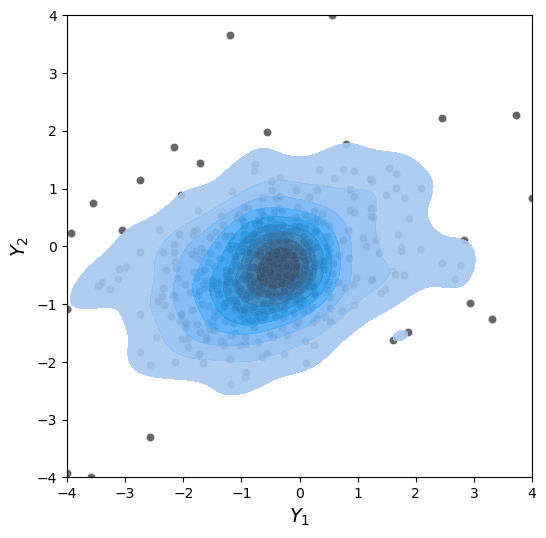

r: 51, c: 1


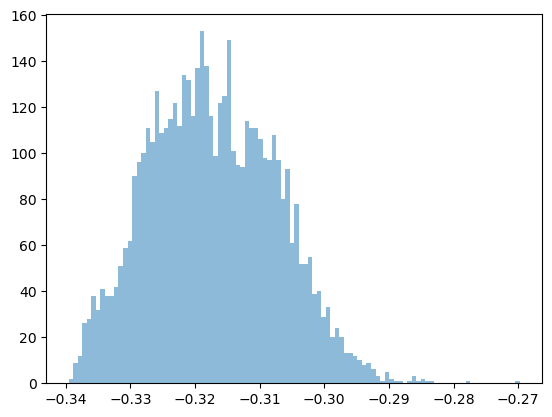

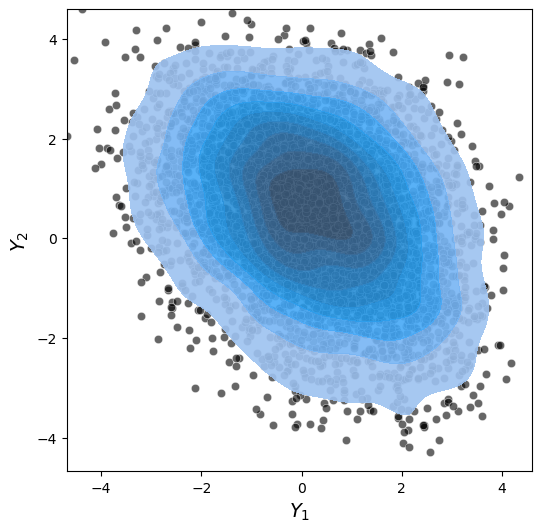

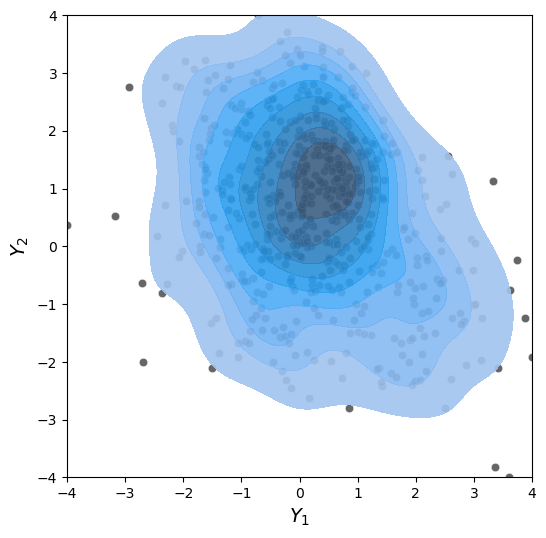

r: 52, c: 2


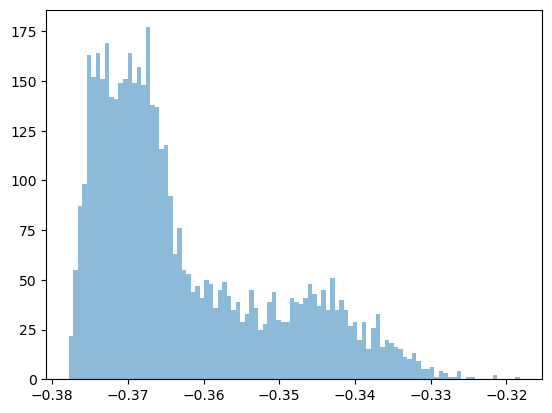

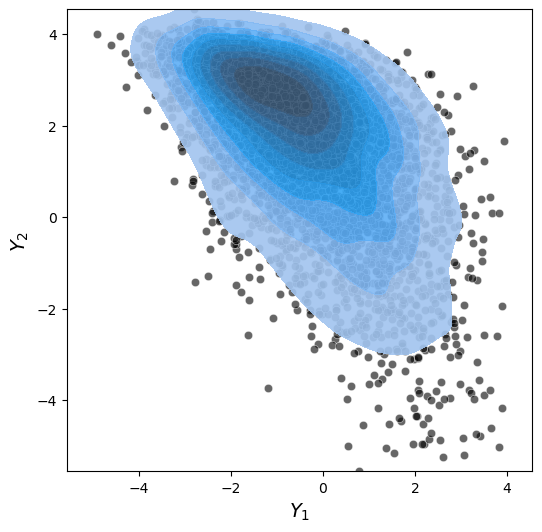

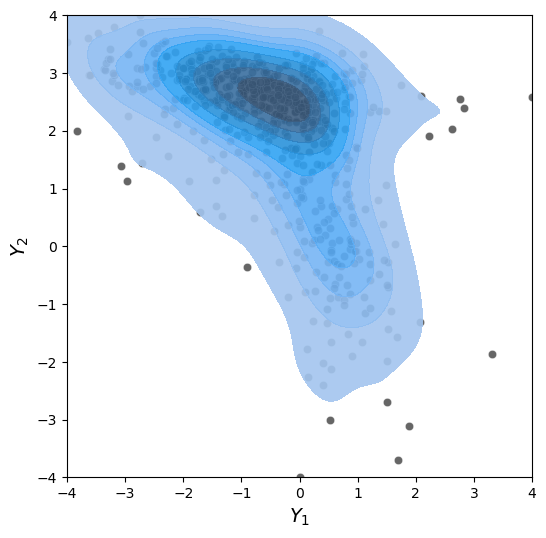

r: 65, c: 15


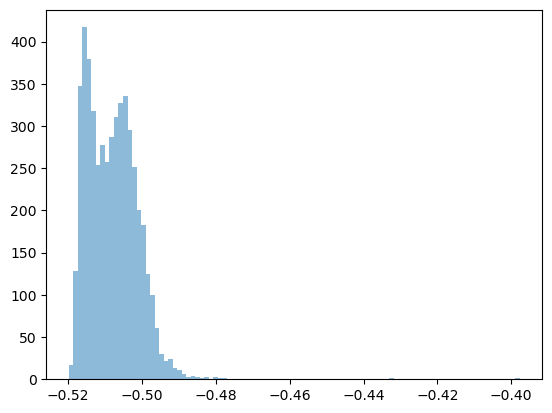

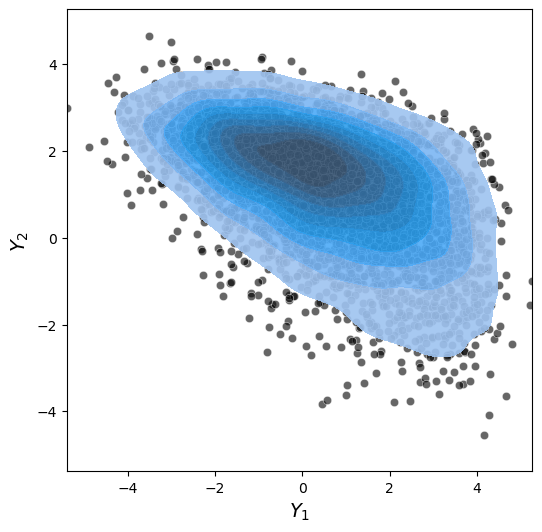

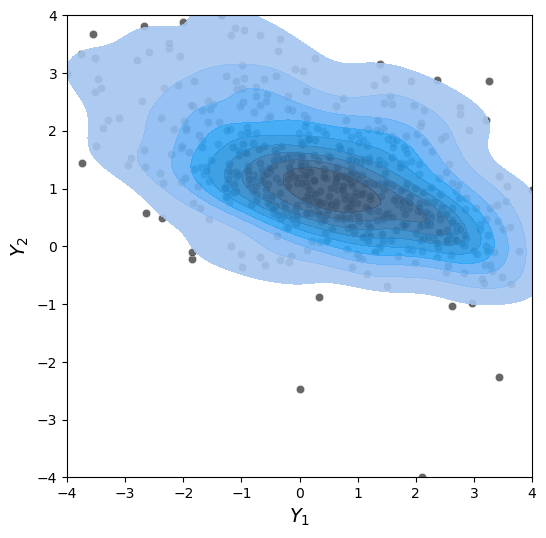

r: 71, c: 21


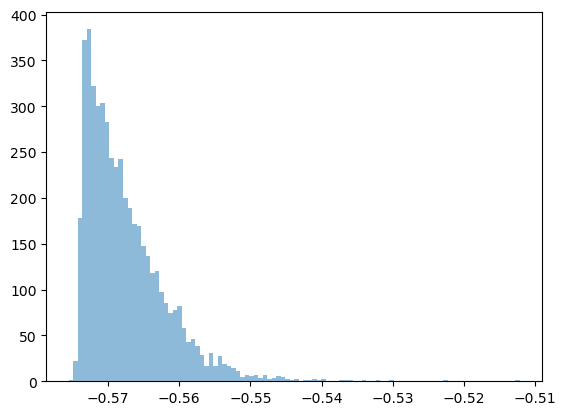

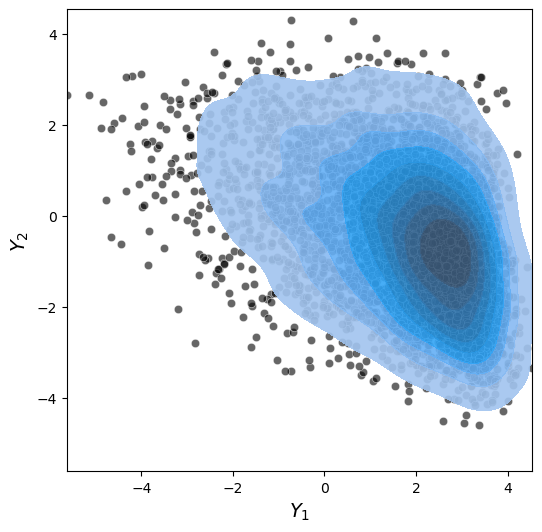

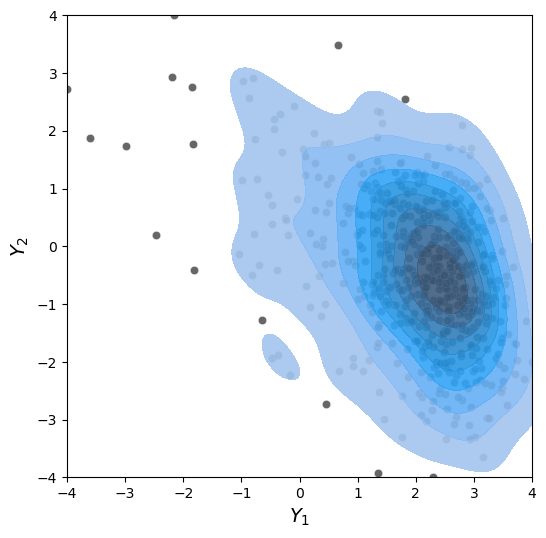

r: 72, c: 22


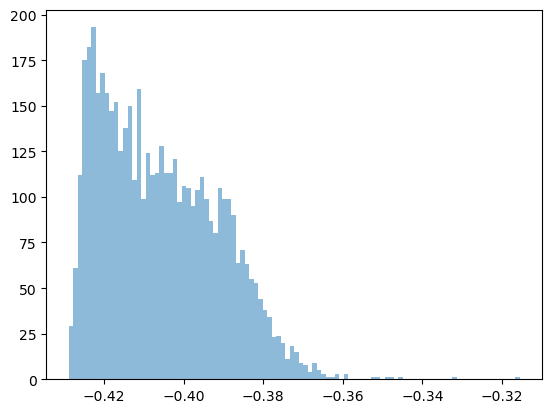

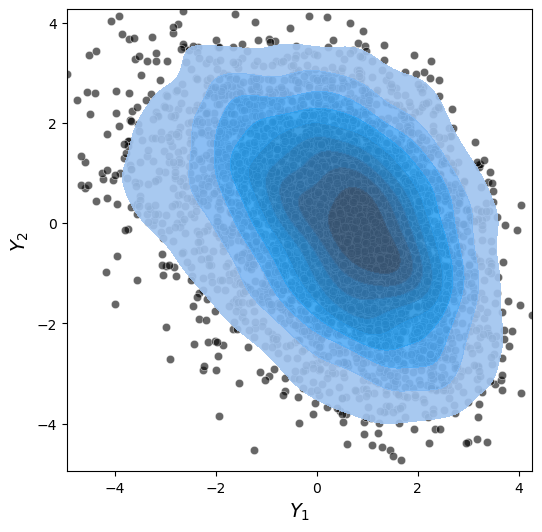

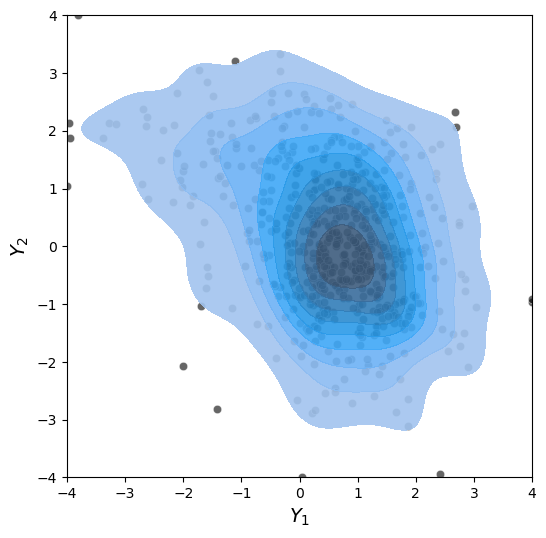

r: 76, c: 26


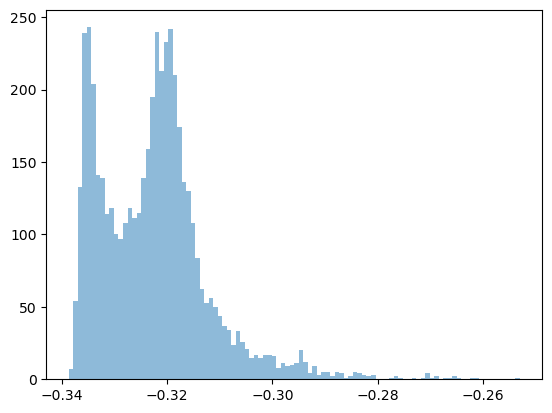

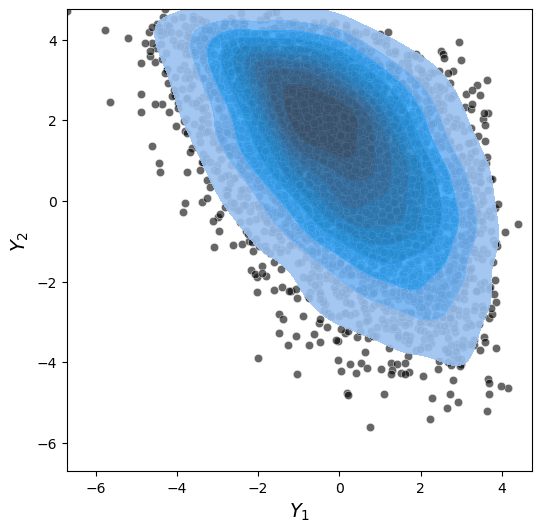

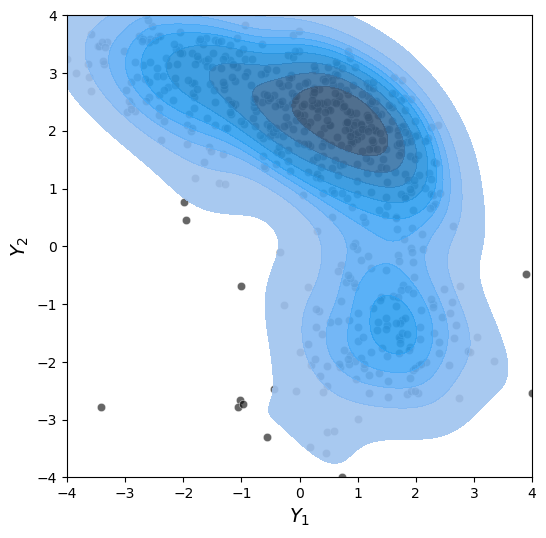

r: 81, c: 31


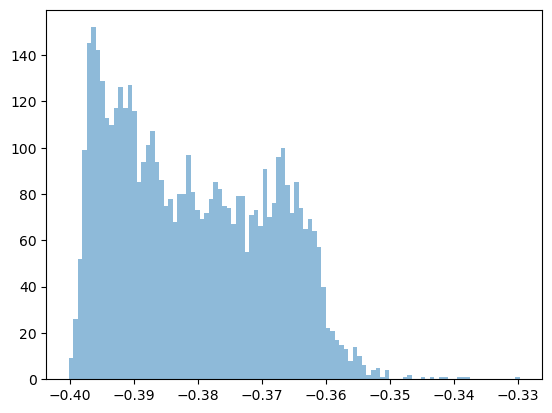

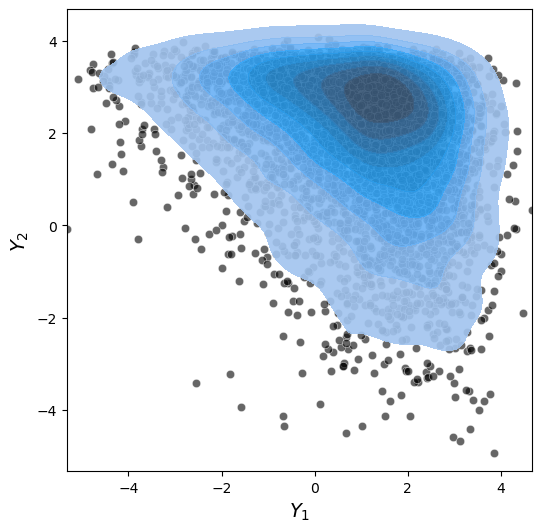

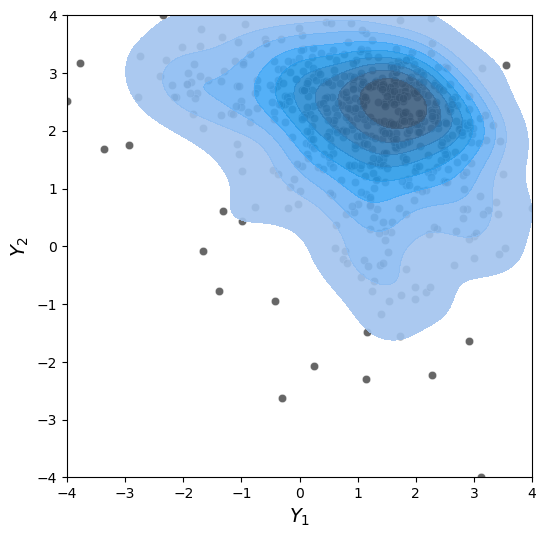

r: 83, c: 33


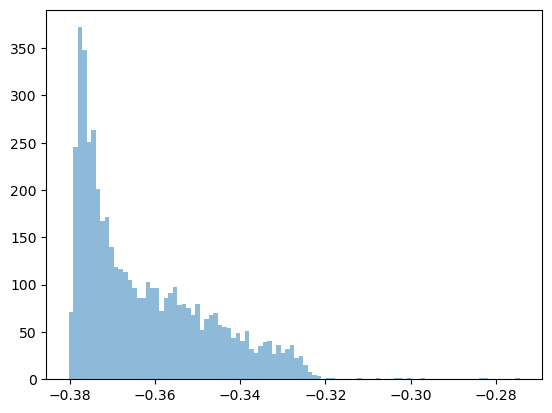

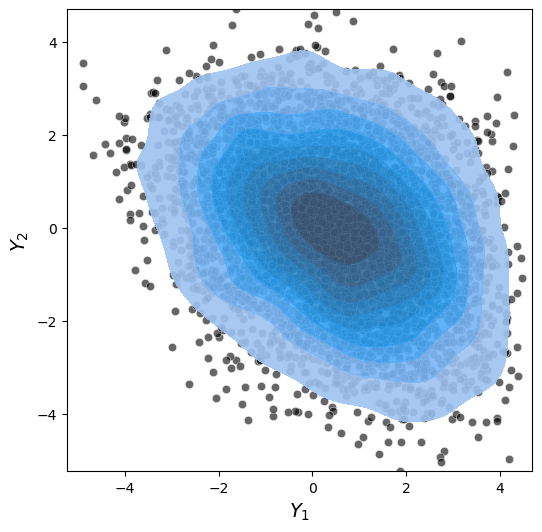

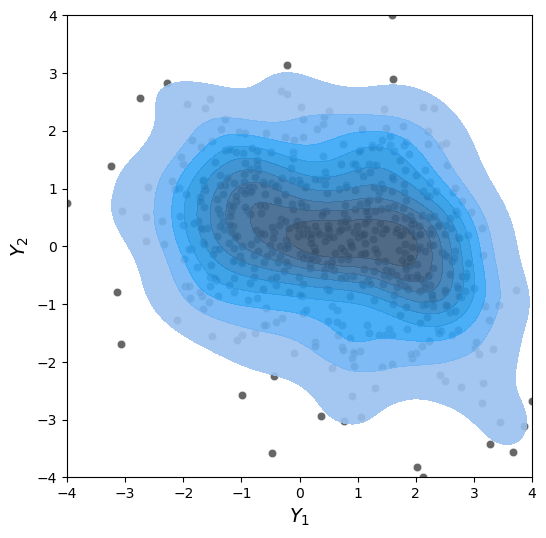

r: 86, c: 36


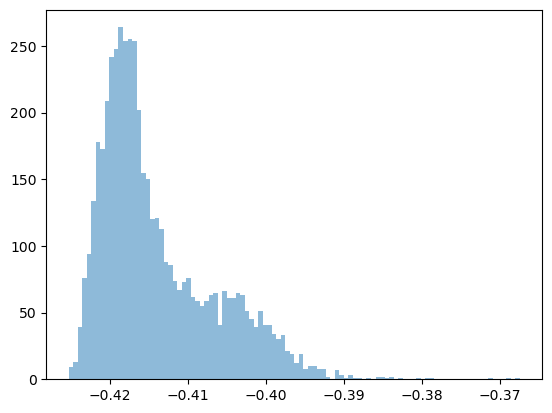

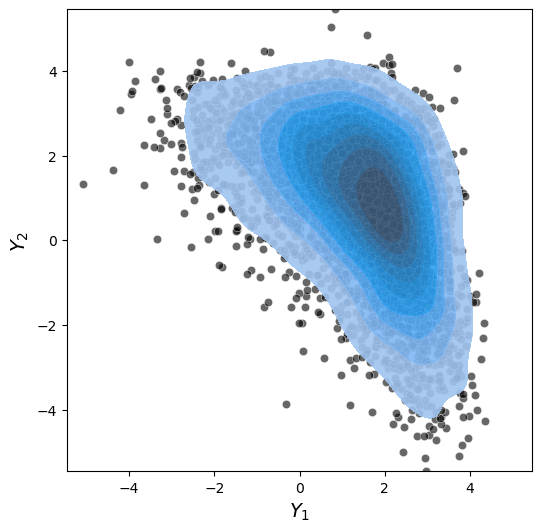

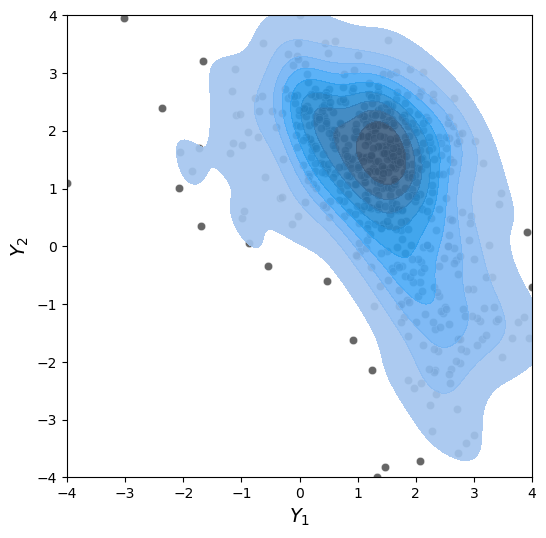

r: 89, c: 65


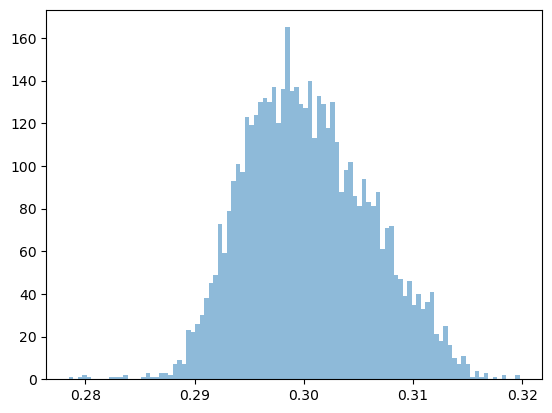

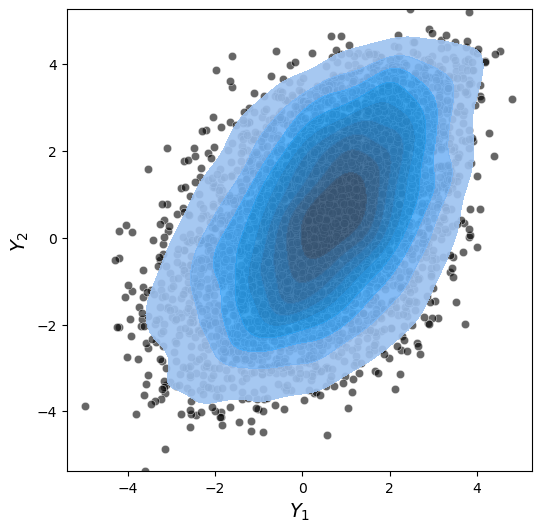

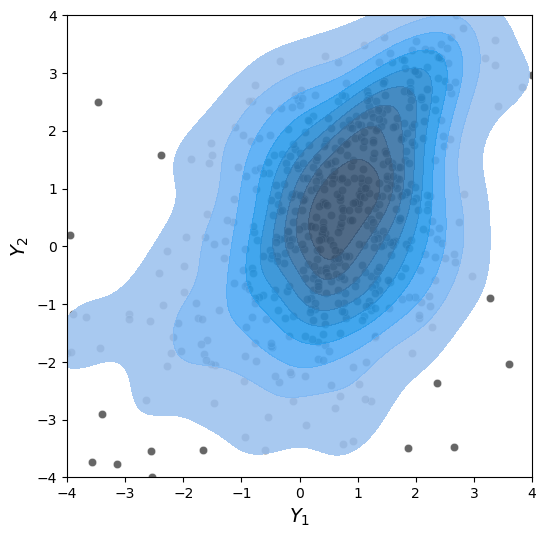

r: 90, c: 69


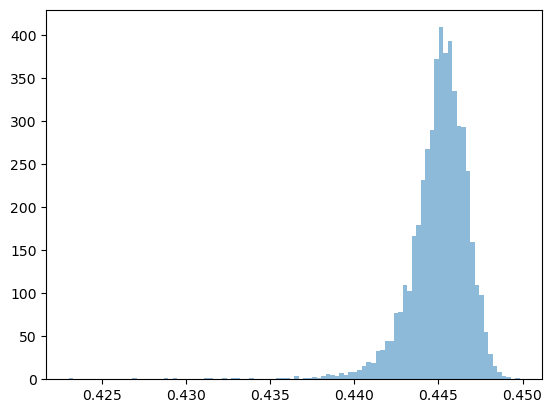

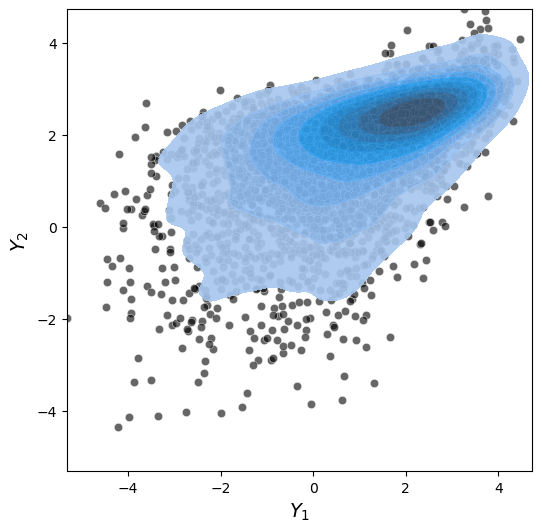

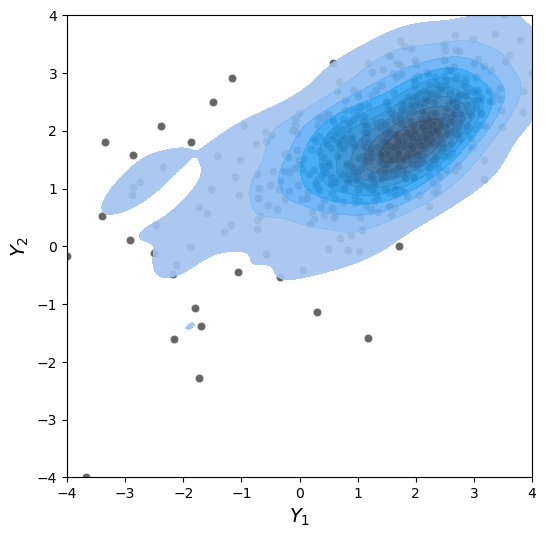

r: 94, c: 44


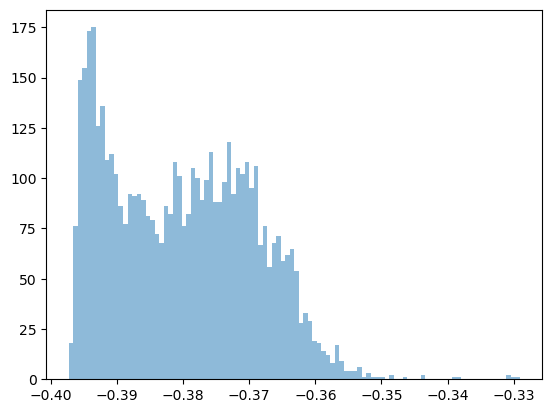

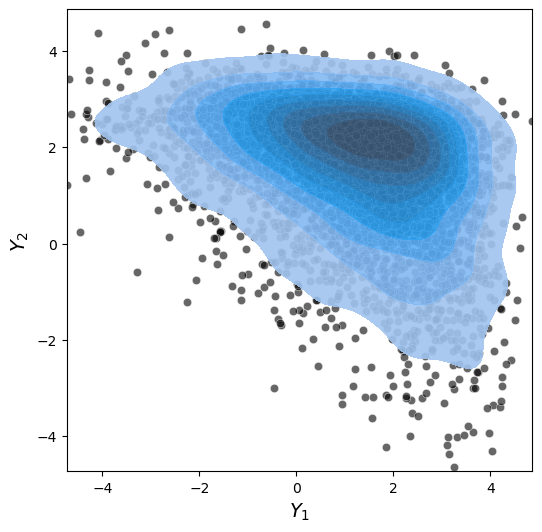

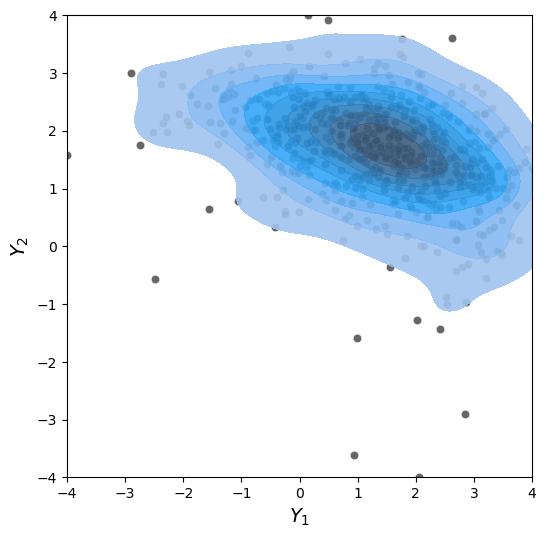

r: 98, c: 82


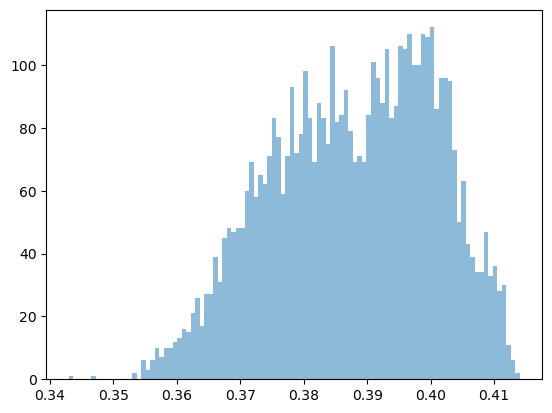

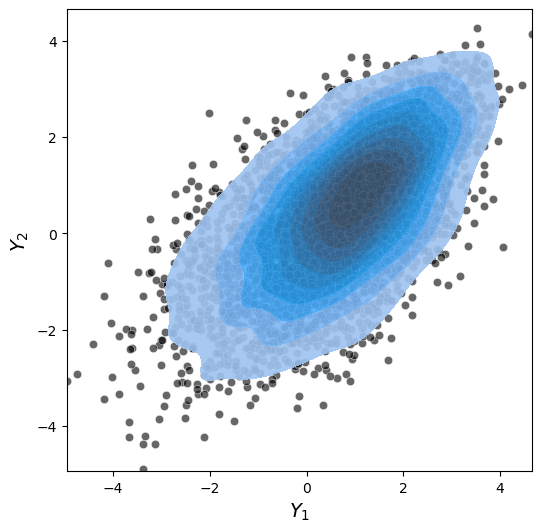

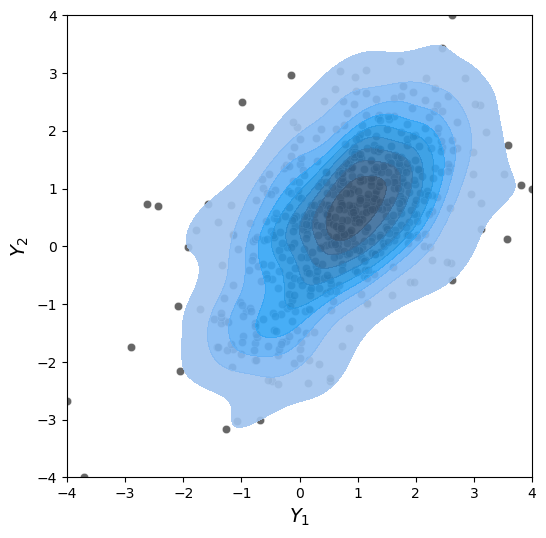

In [430]:
r = conditional_independence_table2[conditional_independence_table2["cond_correlation_abs_mean"] > 0.3]["var_row"].values
c = conditional_independence_table2[conditional_independence_table2["cond_correlation_abs_mean"] > 0.3]["var_col"].values

for i in range(len(r)):
    print(f"r: {r[i]}, c: {c[i]}")

    plt.hist(local_pseudo_cond_corr_matrix[:,r[i],c[i]], bins=100, alpha=0.5, label=f"r: {r[i]}, c: {c[i]}")
    plt.show()
    
    model.plot_densities(synthetic_samples[:,[r[i],c[i]]])
    
    model.plot_densities(data_train_torch[:,[r[i],c[i]]])
    

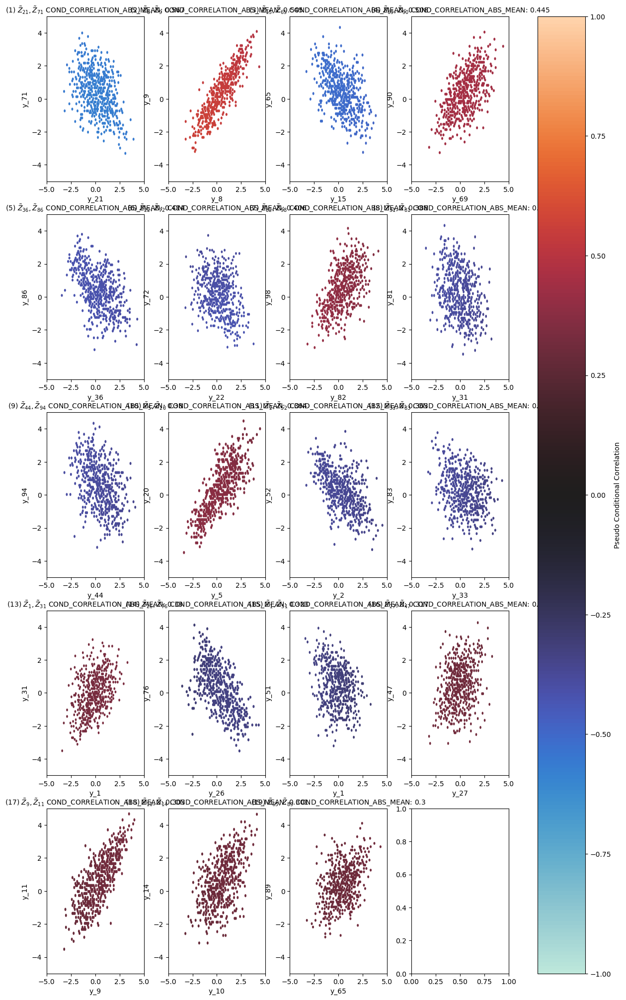

In [426]:
model.plot_conditional_dependence_structure(data=data_train_torch,
                          dependence_metric_threshholding="cond_correlation_abs_mean",
                          minimum_dependence_threshold=0.3, 
                          conditional_independence_table=conditional_independence_table2,
                          x_lim = (-5, 5),
                          y_lim = (-5, 5),
                          after_marginal_transformation = True,
                          )

In [427]:
sum(conditional_independence_table["cond_correlation_abs_mean"] > 0.2)

34

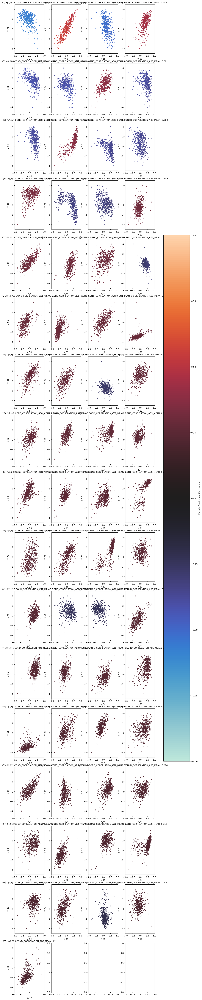

In [428]:
model.plot_conditional_dependence_structure(data=data_train_torch,
                          dependence_metric_threshholding="cond_correlation_abs_mean",
                          minimum_dependence_threshold=0.2, 
                          conditional_independence_table=conditional_independence_table2,
                          x_lim = (-5, 5),
                          y_lim = (-5, 5),
                          after_marginal_transformation = False,
                          )

/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


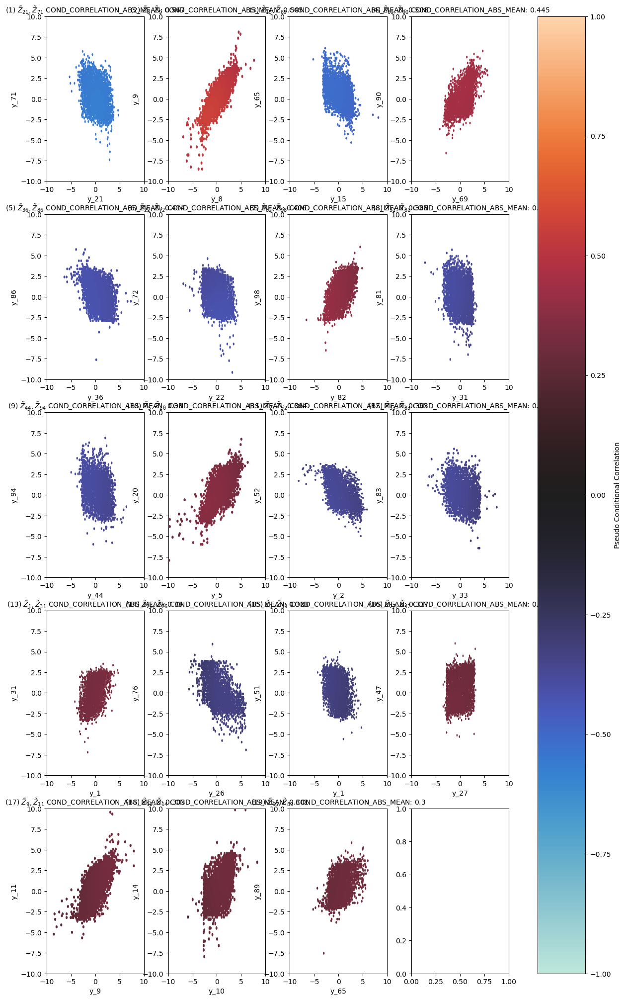

In [431]:
model.plot_conditional_dependence_structure(data=synthetic_samples,
                          dependence_metric_threshholding="cond_correlation_abs_mean",
                          minimum_dependence_threshold=0.3, 
                          conditional_independence_table=conditional_independence_table2,
                          x_lim = (-10, 10),
                          y_lim = (-10, 10),
                          after_marginal_transformation = True,
                          )

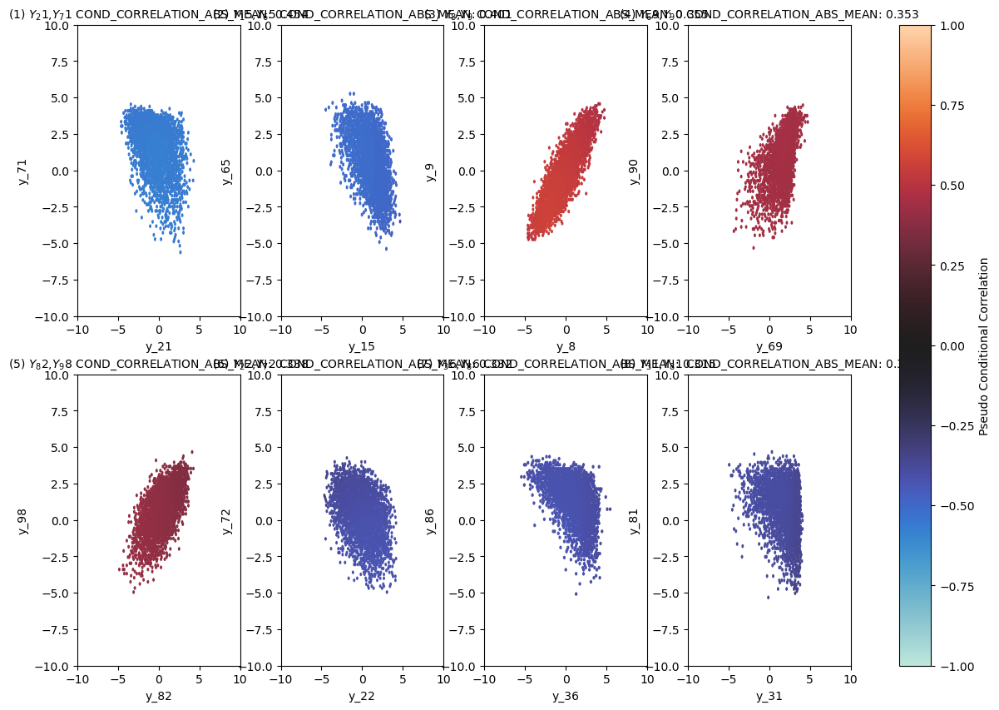

In [432]:
model.plot_conditional_dependence_structure(data=synthetic_samples,
                          dependence_metric_threshholding="cond_correlation_abs_mean",
                          minimum_dependence_threshold=0.3, 
                          conditional_independence_table=conditional_independence_table,
                          x_lim = (-10, 10),
                          y_lim = (-10, 10),
                          after_marginal_transformation = False,
                          )

### 7. there a issue with inverting the splines? Seems so, thus synthetic sampels dont work!!!

In [96]:
model.approximate_transformation_inverse(degree_inverse=100)




In [97]:
model.plot_splines(layer_type="transformation")

### 8. We can see the penalty does push down the conditional correlations here in the hist of differences

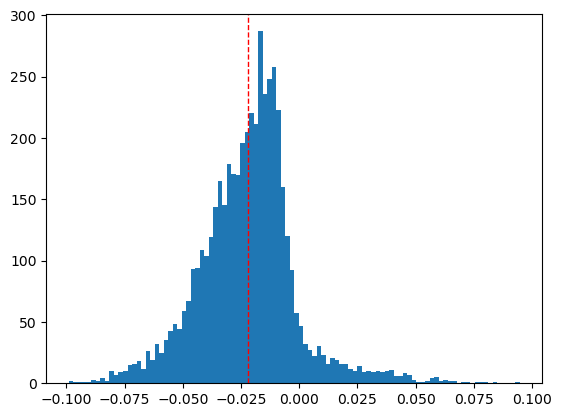

In [440]:
plt.hist(conditional_independence_table2["cond_correlation_abs_mean"] - conditional_independence_table_no2["cond_correlation_abs_mean"], bins=100)
# mean
plt.axvline(np.mean(conditional_independence_table2["cond_correlation_abs_mean"] - conditional_independence_table_no2["cond_correlation_abs_mean"]), color='red', linestyle='dashed', linewidth=1)
plt.show()

### 9. Identifying the Conditional Independence Graph

In [158]:
names_array = data.columns.values

In [159]:
conditional_independence_table_named = conditional_independence_table.copy()
conditional_independence_table_named

,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
0,1,0,0.055809,0.033705,0,0,0.000459,0.020369,0.060612,0.060590
1,2,0,0.036535,0.022377,0,0,0.000360,0.016706,0.047413,0.039499
2,2,1,0.058383,0.035597,0,0,0.000300,0.013087,0.039659,0.036532
3,3,0,0.154349,0.094423,0,0,0.000793,0.034895,0.105048,-0.101178
4,3,1,0.075070,0.047784,0,0,0.000404,0.018395,0.053428,-0.045652
...,...,...,...,...,...,...,...,...,...,...
4945,99,94,0.030377,0.023212,0,0,0.000153,0.008158,0.020263,-0.020190
4946,99,95,0.038849,0.031665,0,0,0.000312,0.017605,0.041134,0.040771
4947,99,96,0.036145,0.029103,0,0,0.000240,0.013244,0.031659,0.031559
4948,99,97,0.032195,0.025913,0,0,0.000319,0.017765,0.042126,0.023082


In [160]:
conditional_independence_table_named["var_col"] = names_array[conditional_independence_table_named["var_col"].values]
conditional_independence_table_named["var_row"] = names_array[conditional_independence_table_named["var_row"].values]

In [161]:
conditional_independence_table_named

,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
0,LTF_expr,XBP1_expr,0.055809,0.033705,0,0,0.000459,0.020369,0.060612,0.060590
1,GATA3_expr,XBP1_expr,0.036535,0.022377,0,0,0.000360,0.016706,0.047413,0.039499
2,GATA3_expr,LTF_expr,0.058383,0.035597,0,0,0.000300,0.013087,0.039659,0.036532
3,AEBP1_expr,XBP1_expr,0.154349,0.094423,0,0,0.000793,0.034895,0.105048,-0.101178
4,AEBP1_expr,LTF_expr,0.075070,0.047784,0,0,0.000404,0.018395,0.053428,-0.045652
...,...,...,...,...,...,...,...,...,...,...
4945,ZNF768_methylation,REPIN1_methylation,0.030377,0.023212,0,0,0.000153,0.008158,0.020263,-0.020190
4946,ZNF768_methylation,USF1_methylation,0.038849,0.031665,0,0,0.000312,0.017605,0.041134,0.040771
4947,ZNF768_methylation,HMG20B_methylation,0.036145,0.029103,0,0,0.000240,0.013244,0.031659,0.031559
4948,ZNF768_methylation,TFDP1_methylation,0.032195,0.025913,0,0,0.000319,0.017765,0.042126,0.023082


In [119]:
conditional_independence_table_named.to_csv("dragon_conditional_independence_table_named.csv", index=False)

In [162]:
conditional_independence_table_named= pd.read_csv("dragon_conditional_independence_table_named.csv")

In [194]:
conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.05]

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_16778/2409950184.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.05]


In [181]:

conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.1]
print(conditional_independence_table_named_subset.shape)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(conditional_independence_table_named_subset)

(327, 10)


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_16778/1937365794.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.1]


,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
2506,SREBF1_methylation,SREBF1_expr,0.673033,0.453671,0,0,0.004178,0.198958,0.551910,-0.551493
2095,HMGA1_methylation,HMGA1_expr,0.620242,0.401009,0,0,0.003833,0.175139,0.506552,-0.505902
44,FOS_expr,EGR1_expr,0.676827,0.355265,0,0,0.004160,0.165491,0.549886,0.545754
4074,ATF6B_methylation,DRAP1_methylation,0.497580,0.353351,0,0,0.003161,0.156833,0.417529,0.417076
4835,PA2G4_methylation,ZNF146_methylation,0.442242,0.337632,0,0,0.002738,0.144787,0.361861,0.361158
2578,STAT1_methylation,STAT1_expr,0.497008,0.332060,0,0,0.003094,0.145316,0.408619,-0.408373
3691,CXXC5_methylation,CXXC5_expr,0.436367,0.315379,0,0,0.002706,0.136340,0.357384,-0.356547
3271,EHF_methylation,EHF_expr,0.432429,0.308402,0,0,0.002680,0.133786,0.353907,-0.353667
4415,REPIN1_methylation,REPIN1_expr,0.388630,0.294312,0,0,0.002436,0.127493,0.321765,-0.321418
3436,KLF6_methylation,KLF6_expr,0.390116,0.277876,0,0,0.002359,0.117235,0.311525,-0.310986


In [182]:
import pandas as pd
import re
from typing import Union

def count_methylation_expr_pairs(data: Union[str, pd.DataFrame],
                                 row_col='var_row',
                                 col_col='var_col',
                                 nrows=100):
    """
    Count rows (first nrows) where one column is <GENE>_methylation and the other is <GENE>_expr
    (order ignored). Returns (count, list_of_matching_row_indices, list_of_matching_pairs).
    `data` can be a filename (CSV/TSV) or a pandas DataFrame.
    """
    # load
    if isinstance(data, pd.DataFrame):
        df = data.copy()
    else:
        # auto-detect separator (works for comma, tab, semicolon, etc.)
        df = pd.read_csv(data, sep=None, engine='python')
    # ensure columns exist
    if row_col not in df.columns or col_col not in df.columns:
        raise ValueError(f"Columns '{row_col}' and/or '{col_col}' not found in the data.")
    df = df.reset_index(drop=True).iloc[:nrows]

    def extract_gene_and_type(s):
        if not isinstance(s, str):
            return None, None
        s = s.strip()
        if s.lower().endswith('_methylation'):
            return s[:-len('_methylation')].strip(), 'methylation'
        if s.lower().endswith('_expr') or s.lower().endswith('_expression'):
            # allow both _expr and _expression just in case
            if s.lower().endswith('_expr'):
                return s[:-len('_expr')].strip(), 'expr'
            else:
                return s[:-len('_expression')].strip(), 'expr'
        return None, None

    matches_idx = []
    matches_pairs = []

    for idx, row in df.iterrows():
        a = row[row_col]
        b = row[col_col]
        gene_a, type_a = extract_gene_and_type(a)
        gene_b, type_b = extract_gene_and_type(b)
        if gene_a is None or gene_b is None:
            continue
        # check complementary types and same gene (case-insensitive)
        if type_a != type_b and gene_a.lower() == gene_b.lower():
            matches_idx.append(idx)
            matches_pairs.append((a, b))

    return len(matches_idx), matches_idx, matches_pairs

In [183]:
conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2]

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_16778/569099620.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2]


,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
2506,SREBF1_methylation,SREBF1_expr,0.673033,0.453671,0,0,0.004178,0.198958,0.551910,-0.551493
2095,HMGA1_methylation,HMGA1_expr,0.620242,0.401009,0,0,0.003833,0.175139,0.506552,-0.505902
44,FOS_expr,EGR1_expr,0.676827,0.355265,0,0,0.004160,0.165491,0.549886,0.545754
4074,ATF6B_methylation,DRAP1_methylation,0.497580,0.353351,0,0,0.003161,0.156833,0.417529,0.417076
4835,PA2G4_methylation,ZNF146_methylation,0.442242,0.337632,0,0,0.002738,0.144787,0.361861,0.361158
2578,STAT1_methylation,STAT1_expr,0.497008,0.332060,0,0,0.003094,0.145316,0.408619,-0.408373
3691,CXXC5_methylation,CXXC5_expr,0.436367,0.315379,0,0,0.002706,0.136340,0.357384,-0.356547
3271,EHF_methylation,EHF_expr,0.432429,0.308402,0,0,0.002680,0.133786,0.353907,-0.353667
4415,REPIN1_methylation,REPIN1_expr,0.388630,0.294312,0,0,0.002436,0.127493,0.321765,-0.321418
3436,KLF6_methylation,KLF6_expr,0.390116,0.277876,0,0,0.002359,0.117235,0.311525,-0.310986


In [185]:
conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2].shape

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_16778/3075667598.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2].shape


(34, 10)

In [186]:
count_methylation_expr_pairs(conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2],
                                 row_col='var_row',
                                 col_col='var_col',
                                 nrows=100)

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_16778/2025287029.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  count_methylation_expr_pairs(conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.2],


(12,
 [0, 1, 5, 6, 7, 8, 9, 12, 15, 16, 25, 28],
 [('SREBF1_methylation', 'SREBF1_expr'),
  ('HMGA1_methylation', 'HMGA1_expr'),
  ('STAT1_methylation', 'STAT1_expr'),
  ('CXXC5_methylation', 'CXXC5_expr'),
  ('EHF_methylation', 'EHF_expr'),
  ('REPIN1_methylation', 'REPIN1_expr'),
  ('KLF6_methylation', 'KLF6_expr'),
  ('LTF_methylation', 'LTF_expr'),
  ('HMGN3_methylation', 'HMGN3_expr'),
  ('GATA3_methylation', 'GATA3_expr'),
  ('IRF6_methylation', 'IRF6_expr'),
  ('ESR1_methylation', 'ESR1_expr')])

In [188]:
conditional_independence_table_named_subset["var_row"].value_counts()

SOX9_expr              10
PA2G4_methylation       9
ZNF768_methylation      9
TFDP1_methylation       8
PA2G4_expr              8
                       ..
ATF4_expr               1
HMGA1_expr              1
CENPB_expr              1
FOS_expr                1
BHLHE40_methylation     1
Name: var_row, Length: 86, dtype: int64

In [189]:
conditional_independence_table_named_subset["var_col"].value_counts()

AEBP1_expr              11
STAT1_expr               9
XBP1_expr                8
DRAP1_expr               8
NFE2L1_expr              8
                        ..
TFDP1_methylation        1
USF1_expr                1
STAT3_methylation        1
SLC2A4RG_methylation     1
ATF6B_methylation        1
Name: var_col, Length: 89, dtype: int64

In [190]:
arr, counts =  np.unique(np.array([conditional_independence_table_named_subset["var_row"],conditional_independence_table_named_subset["var_col"]]),return_counts=True)
pd.DataFrame({"name":arr,
              "counts":counts}).sort_values("counts",ascending=False).head(10)

,name,counts
0,AEBP1_expr,11
70,SOX9_expr,11
90,ZBTB7B_expr,10
82,TRPS1_expr,10
76,STAT1_expr,10
18,CREB3_expr,9
94,ZNF664_expr,9
92,ZNF146_expr,9
81,TFDP1_methylation,9
63,PA2G4_methylation,9


In [195]:
# mask for expr-methylation (either direction)
df = conditional_independence_table_named_subset
mask = (
    (
        df['var_row'].str.contains('methylation') & df['var_col'].str.contains('expr')
    ) |
    (
        df['var_col'].str.contains('methylation') & df['var_row'].str.contains('expr')
    )
)
df_subset = df[mask]

df_subset

,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
2506,SREBF1_methylation,SREBF1_expr,0.673033,0.453671,0,0,0.004178,0.198958,0.551910,-0.551493
2095,HMGA1_methylation,HMGA1_expr,0.620242,0.401009,0,0,0.003833,0.175139,0.506552,-0.505902
2578,STAT1_methylation,STAT1_expr,0.497008,0.332060,0,0,0.003094,0.145316,0.408619,-0.408373
3691,CXXC5_methylation,CXXC5_expr,0.436367,0.315379,0,0,0.002706,0.136340,0.357384,-0.356547
3271,EHF_methylation,EHF_expr,0.432429,0.308402,0,0,0.002680,0.133786,0.353907,-0.353667
...,...,...,...,...,...,...,...,...,...,...
4296,SOX9_methylation,TRPS1_expr,0.067024,0.050276,0,0,0.000422,0.021677,0.055730,-0.055542
1268,XBP1_methylation,SOX9_expr,0.071000,0.050191,0,0,0.000398,0.019589,0.052499,-0.050063
4125,ZBTB7B_methylation,HES1_expr,0.063626,0.050176,0,0,0.000400,0.021785,0.052930,0.052646
2821,HMGN3_methylation,HMG20B_expr,0.066065,0.050127,0,0,0.000393,0.020558,0.051948,-0.051168


In [196]:
df_subset.shape

(411, 10)

In [197]:
np.mean(df_subset["hessian_mean"] < 0)

0.49878345498783455

In [198]:
import re

df = conditional_independence_table_named_subset

# Your current mask
mask = (
    (
        df['var_row'].str.contains('methylation') & df['var_col'].str.contains('expr')
    ) |
    (
        df['var_col'].str.contains('methylation') & df['var_row'].str.contains('expr')
    )
)
df_subset = df[mask].copy()

# Extract the gene/base name (the part before the last '_')
def get_base(var):
    return '_'.join(var.split('_')[:-1])

df_subset['row_base'] = df_subset['var_row'].apply(get_base)
df_subset['col_base'] = df_subset['var_col'].apply(get_base)

# Now subset where these base names are equal
matching_subset = df_subset[df_subset['row_base'] == df_subset['col_base']].copy()

# Clean up if you want to drop the helper columns:
matching_subset = matching_subset.drop(['row_base', 'col_base'], axis=1)

# Resulting DataFrame:
matching_subset

,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
2506,SREBF1_methylation,SREBF1_expr,0.673033,0.453671,0,0,0.004178,0.198958,0.551910,-0.551493
2095,HMGA1_methylation,HMGA1_expr,0.620242,0.401009,0,0,0.003833,0.175139,0.506552,-0.505902
2578,STAT1_methylation,STAT1_expr,0.497008,0.332060,0,0,0.003094,0.145316,0.408619,-0.408373
3691,CXXC5_methylation,CXXC5_expr,0.436367,0.315379,0,0,0.002706,0.136340,0.357384,-0.356547
3271,EHF_methylation,EHF_expr,0.432429,0.308402,0,0,0.002680,0.133786,0.353907,-0.353667
4415,REPIN1_methylation,REPIN1_expr,0.388630,0.294312,0,0,0.002436,0.127493,0.321765,-0.321418
3436,KLF6_methylation,KLF6_expr,0.390116,0.277876,0,0,0.002359,0.117235,0.311525,-0.310986
1276,LTF_methylation,LTF_expr,0.410683,0.269193,0,0,0.002566,0.119458,0.339014,-0.338967
2800,HMGN3_methylation,HMGN3_expr,0.336577,0.255856,0,0,0.002172,0.113229,0.286954,-0.286829
1328,GATA3_methylation,GATA3_expr,0.365420,0.251652,0,0,0.002345,0.113396,0.309819,-0.309597


In [199]:
matching_subset.shape

(27, 10)

In [200]:
np.mean(matching_subset["hessian_mean"] < 0)

0.9259259259259259

In [92]:
arr, counts =  np.unique(np.array([df_subset["var_row"],df_subset["var_col"]]),return_counts=True)
pd.DataFrame({"name":arr,
              "counts":counts}).sort_values("counts",ascending=False).head(10)

,name,counts
55,STAT1_expr,6
0,AEBP1_expr,4
47,REPIN1_methylation,4
20,FOS_methylation,4
11,CXXC5_expr,3
40,KLF6_methylation,3
35,IRX3_methylation,3
23,GATA3_methylation,3
57,TRPS1_expr,3
15,EHF_expr,3


In [95]:
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_col"] == "SOX9_expr"][["var_row","var_col"]])
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_row"] == "SOX9_expr"][["var_row","var_col"]])

               var_row    var_col
1583  ATF4_methylation  SOX9_expr
       var_row       var_col
906  SOX9_expr    AEBP1_expr
934  SOX9_expr      EHF_expr
933  SOX9_expr     HES1_expr
938  SOX9_expr    CEBPB_expr
931  SOX9_expr     IRF6_expr
903  SOX9_expr     XBP1_expr
924  SOX9_expr   SREBF1_expr
939  SOX9_expr    CXXC5_expr
941  SOX9_expr    STAT3_expr
923  SOX9_expr  CREB3L4_expr


In [94]:
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_col"] == "AEBP1_expr"][["var_row","var_col", "hessian_mean"]])
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_row"] == "AEBP1_expr"][["var_row","var_col", "hessian_mean"]])

                 var_row     var_col  hessian_mean
139            SOX4_expr  AEBP1_expr      0.224468
303           HMGN3_expr  AEBP1_expr     -0.201648
906            SOX9_expr  AEBP1_expr     -0.189170
256           CENPB_expr  AEBP1_expr      0.192132
4563  HMG20B_methylation  AEBP1_expr     -0.161107
438            HES1_expr  AEBP1_expr     -0.153627
3006    IRF6_methylation  AEBP1_expr      0.146243
409           CEBPD_expr  AEBP1_expr     -0.133775
279           CREB3_expr  AEBP1_expr      0.121249
1329   GATA3_methylation  AEBP1_expr      0.129249
3919    IRX3_methylation  AEBP1_expr     -0.112489
Empty DataFrame
Columns: [var_row, var_col, hessian_mean]
Index: []


In [68]:
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_col"] == "REPIN1_methylation"][["var_row","var_col"]])
print(conditional_independence_table_named_subset[conditional_independence_table_named_subset["var_row"] == "REPIN1_methylation"][["var_row","var_col"]])

Empty DataFrame
Columns: [var_row, var_col]
Index: []
                 var_row             var_col
4415  REPIN1_methylation         REPIN1_expr
4442  REPIN1_methylation  SREBF1_methylation
4416  REPIN1_methylation           USF1_expr
4462  REPIN1_methylation  ZBTB7B_methylation
4424  REPIN1_methylation   AEBP1_methylation
4437  REPIN1_methylation  NFE2L1_methylation
4389  REPIN1_methylation          TRPS1_expr
4407  REPIN1_methylation          CXXC5_expr


In [453]:
conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.1]
print(conditional_independence_table_named_subset.shape)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(conditional_independence_table_named_subset)

(327, 10)


/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_11471/1385416253.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_named_subset = conditional_independence_table_named.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table_named["cond_correlation_abs_mean"]>0.1]


,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
2506,SREBF1_methylation,SREBF1_expr,0.673033,0.453671,0,0,0.004178,0.198958,0.551910,-0.551493
2095,HMGA1_methylation,HMGA1_expr,0.620242,0.401009,0,0,0.003833,0.175139,0.506552,-0.505902
44,FOS_expr,EGR1_expr,0.676827,0.355265,0,0,0.004160,0.165491,0.549886,0.545754
4074,ATF6B_methylation,DRAP1_methylation,0.497580,0.353351,0,0,0.003161,0.156833,0.417529,0.417076
4835,PA2G4_methylation,ZNF146_methylation,0.442242,0.337632,0,0,0.002738,0.144787,0.361861,0.361158
2578,STAT1_methylation,STAT1_expr,0.497008,0.332060,0,0,0.003094,0.145316,0.408619,-0.408373
3691,CXXC5_methylation,CXXC5_expr,0.436367,0.315379,0,0,0.002706,0.136340,0.357384,-0.356547
3271,EHF_methylation,EHF_expr,0.432429,0.308402,0,0,0.002680,0.133786,0.353907,-0.353667
4415,REPIN1_methylation,REPIN1_expr,0.388630,0.294312,0,0,0.002436,0.127493,0.321765,-0.321418
3436,KLF6_methylation,KLF6_expr,0.390116,0.277876,0,0,0.002359,0.117235,0.311525,-0.310986


In [454]:
conditional_independence_table_connected = conditional_independence_table.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table["cond_correlation_abs_mean"]>0.05]
connected_columns = np.unique(np.hstack([conditional_independence_table_connected["var_row"], conditional_independence_table_connected["var_col"]]))

/var/folders/57/_f_fv4s97k300zslnyj86dxc0000gn/T/ipykernel_11471/4098561915.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  conditional_independence_table_connected = conditional_independence_table.sort_values("cond_correlation_abs_mean",ascending=False)[conditional_independence_table["cond_correlation_abs_mean"]>0.05]


In [455]:
# subset to only the rows wher row_col and var_row is in connected_columns
conditional_independence_table_connected_subset = conditional_independence_table[conditional_independence_table["var_row"].isin(connected_columns) & conditional_independence_table["var_col"].isin(connected_columns)]
conditional_independence_table_connected_subset.shape

(4950, 10)

In [456]:
names_array_subset = names_array[connected_columns]
names_array_subset.shape

(100,)

In [457]:
model_plot = GTM(number_variables = len(connected_columns))

In [458]:
conditional_independence_table_connected_subset["var_col"] = names_array[conditional_independence_table_named["var_col"].values]

IndexError: arrays used as indices must be of integer (or boolean) type

In [459]:
# turn columns var_col and var_row into numbers ordered from 0 to length of connected_columns
conditional_independence_table_connected_subset["var_col"] = conditional_independence_table_connected_subset["var_col"].astype('category').cat.codes
conditional_independence_table_connected_subset["var_row"] = conditional_independence_table_connected_subset["var_row"].astype('category').cat.codes

In [460]:
conditional_independence_table_connected_subset

,var_row,var_col,precision_abs_mean,cond_correlation_abs_mean,kld,iae,global_normed_hessian_abs_mean,normed_hessian_abs_mean,hessian_abs_mean,hessian_mean
0,0,0,0.055809,0.033705,0,0,0.000459,0.020369,0.060612,0.060590
1,1,0,0.036535,0.022377,0,0,0.000360,0.016706,0.047413,0.039499
2,1,1,0.058383,0.035597,0,0,0.000300,0.013087,0.039659,0.036532
3,2,0,0.154349,0.094423,0,0,0.000793,0.034895,0.105048,-0.101178
4,2,1,0.075070,0.047784,0,0,0.000404,0.018395,0.053428,-0.045652
...,...,...,...,...,...,...,...,...,...,...
4945,98,94,0.030377,0.023212,0,0,0.000153,0.008158,0.020263,-0.020190
4946,98,95,0.038849,0.031665,0,0,0.000312,0.017605,0.041134,0.040771
4947,98,96,0.036145,0.029103,0,0,0.000240,0.013244,0.031659,0.031559
4948,98,97,0.032195,0.025913,0,0,0.000319,0.017765,0.042126,0.023082


There are 316 connections above  0.1


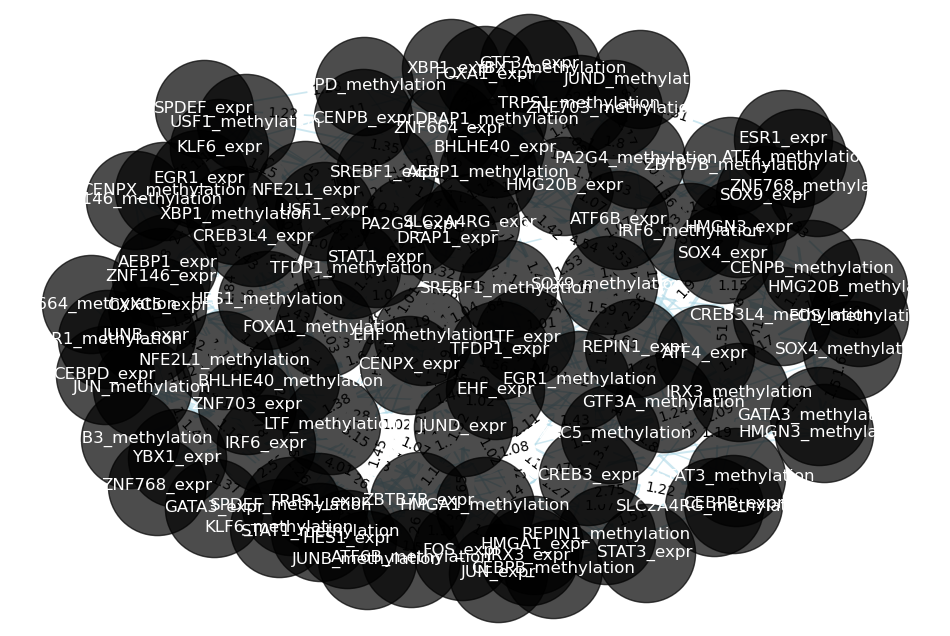

In [468]:
model_plot.plot_conditional_dependence_graph(
                                            conditional_independence_table=conditional_independence_table_connected_subset,
                                              dependence_metric="cond_correlation_abs_mean", 
                                              minimum_dependence_threshold=0.1, 
                                              pair_plots=False,
                                              #data=data_train_torch.detach(), 
                                              names=names_array_subset,
                                              #k=1, 
                                              #seed_graph=42
                                              )

In [463]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

def plot_graph_conditional_independencies(
    abs_array,
    gene_names,
    min_abs_mean=0.1,
    storage=None,
    pos_list=None,
    pos_tuple_list=None,
    k=1.5,
    seed_graph=42,
    show_plot=True,
):
    edge_array = np.tril(abs_array, -1)
    edge_array[edge_array < min_abs_mean] = 0

    print("There are", sum(sum(edge_array > 0)), "connections above ", min_abs_mean)

    G = nx.from_numpy_array(edge_array * 10)  # **2 * 10
    keys = list(range(len(gene_names)))
    values = gene_names
    mapping = {k: v for k, v in zip(keys, values)}
    G = nx.relabel_nodes(G, mapping)
    G.edges(data=True)

    widths = nx.get_edge_attributes(G, "weight")
    nodelist = G.nodes()

    values = np.round(list(widths.values()), 4)
    edge_labels = {k: v for k, v in zip(widths.keys(), values)}

    # Old
    plt.figure(figsize=(24, 16))

    pos = nx.spring_layout(G, weight="weight", seed=seed_graph, k=k)

    if pos_list is not None:
        for i in range(len(pos_list)):
            pos[pos_list[i]] = pos_tuple_list[i]

    nx.draw_networkx_nodes(
        G, pos, nodelist=nodelist, node_size=5000, node_color="black", alpha=0.7
    )
    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=widths.keys(),
        width=list(widths.values()),
        edge_color="lightblue",
        alpha=1,
    )
    nx.draw_networkx_labels(
        G, pos=pos, labels=dict(zip(gene_names, nodelist)), font_color="white"
    )
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10)
    plt.box(False)
    if storage is not None:
        plt.savefig(storage)
    if show_plot == True:
        plt.show()
    else:
        plt.close(fig)

In [467]:
dependence_metric = "cond_correlation_abs_mean"
ci_matrix = torch.zeros([len(connected_columns), len(connected_columns)])
for row in conditional_independence_table_connected_subset.iterrows():
    row = row[1]
    ci_matrix[int(row["var_row"]), int(row["var_col"])] = row[dependence_metric]

There are 316 connections above  0.1


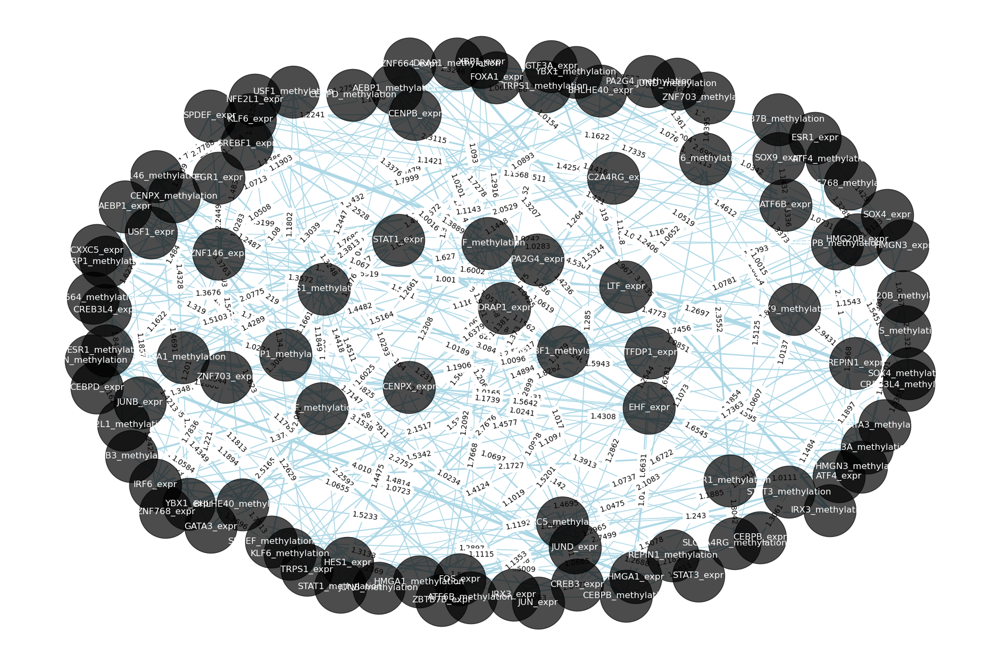

In [466]:
plot_graph_conditional_independencies(
    ci_matrix.numpy(),
    names_array_subset,
    min_abs_mean=0.1,
    storage=None,
    pos_list=None,
    pos_tuple_list=None,
    k=2,
    seed_graph=42,
    show_plot=True,
)